# 2 Markov Chain



## 2.1 Requirements

In [581]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    accuracy_score, recall_score, precision_score,
    precision_recall_curve, average_precision_score,
)
import io, base64
import matplotlib.pyplot as plt
from IPython.display import HTML, display

## 2.2 Data

In [582]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


## 2.3 Performance Metrics

Below are the functions for all the performance metrics which will be looked at throughout this notebook. --- 

In [583]:
import io, base64
from IPython.display import display, HTML

ys = {"train": y_tr, "val": y_va}   # target arrays per split (test deliberately excluded)

_KEYS = {"train": ("p_tr", "sc_tr"), "val": ("p_va", "sc_va")}

def _probs(m, split):
    p_key, sc_key = _KEYS[split]          # KeyError if someone asks for "test"
    if p_key in m:
        return np.asarray(m[p_key])
    return m["platt"].predict_proba(np.asarray(m[sc_key]).reshape(-1, 1))[:, 1]

def _grid(n, ncols=2, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p = _probs(m, split)
        fpr, tpr, _ = roc_curve(ys[split], p)
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p_, r_, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r_, p_, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="val", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="val", bins=40):
    sc_key = _KEYS[split][1]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

def best_threshold(m, y_val, y_split="val"):
    fpr, tpr, thr = roc_curve(y_val, _probs(m, y_split))
    return thr[np.argmax(tpr - fpr)]

def plot_confusion(models, ys=ys, split="val", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

def show_row(*calls, width=330):
    imgs, _show = [], plt.show
    plt.show = lambda *a, **k: None
    try:
        for call in calls:
            call()
            fig = plt.gcf()
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
            plt.close(fig)
            imgs.append(base64.b64encode(buf.getvalue()).decode())
    finally:
        plt.show = _show
    html = "".join(f"<img src='data:image/png;base64,{b}' style='width:{width}px'>" for b in imgs)
    display(HTML(f"<div style='display:flex;flex-wrap:wrap;gap:8px'>{html}</div>"))

## 2.4 Motivations

We decided to continue with a Markov chain because the payment data is already a time-ordered chain of each customer's behaviour. A chain naturally models the data as transitions between a fixed set of states. It is cheap to fit, requires minimal tuning, and can be interpreted directly. In the original model, defaulters and non-defaulters were pooled to create a single transition matrix. The first model was better than base-rate guessing (see 2.5.3 Log-Loss: a constant 22.1% prediction gives about 0.528, against about 0.461 for the baseline on test). However, it has several disadvantages, which we examine below so that we can identify ways to improve it.

**Problems with the baseline**

1. **Pooling the classes.**
    - Pooling the two classes together hides the patterns of each class and averages their behaviour. This is why the next model will be trained on each class separately, so that their differences in behaviour can be better identified.
    - Averaging state transitions compresses extremes towards the mean, which leads to low risk being overestimated and high risk being underestimated. This is likely why the model does well on non-defaulters but is almost 50/50 on defaulters (see the confusion matrix in 2.5.3: test set, threshold 0.344, recall 0.54, specificity 0.85).
2. **Compressed statuses.** The baseline maps the statuses -2, -1 and 0 to a single "current" state and merges every status of three or more months late into one state, which might be hiding information that could improve the model.
3. **Missing amounts.** Payment status does not give exact information about how large the late payments are. For example, £10 and £1000 one month late are treated the same way.
4. **One-step memory.** The model is a one-step transition, so it only cares about the latest state. It treats someone who has been a month late for six months the same as someone who was current for the first five months and late only in the most recent one.

In this section we will directly target each of these issues with adjustments to our model. Each adjustment is introduced in its own section below.

1. Firstly, creating a two-class chain so that class-specific patterns can be identified.
2. Varying the segmentation of states, merging states that carry little information while keeping those that distinguish the classes, so the transition estimates stay reliable.
3. Next, supplementing the chain with specific amounts by using the `BILL_AMT` and `PAY_AMT` data in conjunction.
4. Finally, using a higher-order Markov chain to allow dependence on more than just the previous state.

These adjustments all have trade-offs of their own, so they will not definitively improve the model. Changing the states will not always give an obviously correct segmentation. Defining states using `BILL_AMT` and `PAY_AMT`, or conditioning on more history, increases the number of rows in the transition matrix, so each row has fewer observations and its estimates become less reliable. This is why, as adjustments are made, it is important to compare against the baseline model to see how the results are affected, and to compare each model against one another to determine which is the most suitable for this problem. Metrics we will consider include: AUC, log loss, Brier score, calibration, and stability between validation and test.

## 2.5 Baseline Markov Chain Model

The code from the first sprint has been adjusted to fit with our consistent split of data so that the comparisons are completely fair. This single chain model is a good starting point firstly because it is simple and inexpensive with only 4 states. 

### 2.5.1 Model definition

Let $s_{i,t}\in\{0,\dots,K-1\}$ be customer $i$'s state in month $t$ (with $K=4$), $s_{i,T}$ their latest state, $y_i\in\{0,1\}$ whether they default next month, and $\pi$ the training default rate. Everything below uses the training split only.






In [584]:
state_names = ["current", "1_month_late", "2_months_late", "3plus_months_late"]
K_ow = 4

def to_state_ow(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p <= 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s
S_tr = to_state_ow(train[pay_cols].values)
S_va = to_state_ow(validation[pay_cols].values)
S_te = to_state_ow(test[pay_cols].values)
y_tr_a, y_va_a, y_te_a = (np.asarray(v).astype(int) for v in (y_tr, y_va, y_te))

**1. Transition matrix with Laplace smoothing**

The probability for each entry is calculated with laplace smoothing to prevent 0 probablilties when data is not substantial enough to justify 
$$
P_{ab} \;=\; \frac{N_{ab}+1}{\sum_{b'} N_{ab'} + K},
\qquad
N_{ab} = \sum_i \sum_{t=1}^{T-1} \mathbf{1}\!\left[s_{i,t}=a,\; s_{i,t+1}=b\right]
$$


In [585]:
counts = np.ones((K_ow, K_ow))
for a, b in zip(S_tr[:, :-1].ravel(), S_tr[:, 1:].ravel()):
    counts[a, b] += 1
P_ow = counts / counts.sum(axis=1, keepdims=True)

**2. Default rate by latest state with shrink**

$$
r_k \;=\; \frac{\sum_i y_i\,\mathbf{1}\!\left[s_{i,T}=k\right] + \lambda\,\pi}{n_k + \lambda},
\qquad
n_k = \sum_i \mathbf{1}\!\left[s_{i,T}=k\right]
$$

where $\lambda$ is the shrink parameter (acts like $\lambda$ extra customers with the average default rate which pushes towards the global rate).

In [586]:
latest_tr = S_tr[:, -1]
global_rate = y_tr_a.mean()
shrink = 20
risk_by_state = np.array([
    (y_tr_a[latest_tr == k].sum() + shrink * global_rate) / ((latest_tr == k).sum() + shrink)
    for k in range(K_ow)
])

**3. One-step Markov projection**

$$
\hat p_i \;=\; \sum_{j=0}^{K-1} P_{s_{i,T},\,j}\; r_j
$$

The predicted default probability is the expected default rate of next month's state, given the latest state.

In [587]:
def predict_onestep(S):
    return P_ow[S[:, -1]] @ risk_by_state
p_mk_onestep_va = predict_onestep(S_va)
p_mk_onestep_te = predict_onestep(S_te)
pooled = dict(p_tr=predict_onestep(S_tr), p_va=p_mk_onestep_va, p_te=p_mk_onestep_te)

### 2.5.2 Shrink Analysis

The only parameter requiring tuning in the baseline is the shrink value $\lambda$, which controls how strongly each state's default rate $r_k$ is pulled towards the global training default rate $\pi$. A larger $\lambda$ means more shrinkage, any states lacking in data are affected most. We varied $\lambda$ between 0 and 2000 and evaluated each setting on the validation set:

| $\lambda$ | $r_0$ | $r_1$ | $r_2$ | $r_3$ | AUC | Log loss |
|---|---|---|---|---|---|---|
| 0 | 0.142 | 0.322 | 0.692 | 0.708 | 0.7098 | 0.4574 |
| 20 | 0.142 | 0.322 | 0.686 | 0.676 | 0.7098 | 0.4579 |
| 200 | 0.143 | 0.314 | 0.640 | 0.507 | 0.7098 | 0.4623 |
| 2000 | 0.152 | 0.274 | 0.430 | 0.282 | 0.7093 | 0.4835 |

AUC is almost unchanged across the whole range. The model produces only four distinct predictions (one per latest state), so AUC depends only on how those four values are ordered, and shrinkage barely alters that ordering. Log loss does change, and it rises as $\lambda$ increases, because heavy shrinkage pushes every state's risk towards the average and weakens the separation between states. The state 3+ rate falls fastest (0.708 to 0.282), which suggests it has far fewer customers than the others.

We chose $\lambda = 20$. It costs only about 0.0006 in log loss compared with no shrinkage, and it protects the estimate for the rarest state from being driven by a handful of customers. Because $\lambda$ was compared on the validation set, the final comparison of models uses the held-out test set.

In [588]:
for s in [0, 20, 200, 2000]:
    r = np.array([(y_tr_a[latest_tr == k].sum() + s * global_rate) /
                  ((latest_tr == k).sum() + s) for k in range(K_ow)])
    p = P_ow[S_va[:, -1]] @ r
    print(s, r.round(3), "order", np.argsort(r), "AUC", round(roc_auc_score(y_va_a, p), 5),
          "logloss", round(log_loss(y_va_a, p), 5))

0 [0.142 0.322 0.692 0.708] order [0 1 2 3] AUC 0.70983 logloss 0.45736
20 [0.142 0.322 0.686 0.676] order [0 1 3 2] AUC 0.70983 logloss 0.45792
200 [0.143 0.314 0.64  0.507] order [0 1 3 2] AUC 0.70983 logloss 0.46225
2000 [0.152 0.274 0.43  0.282] order [0 1 3 2] AUC 0.70931 logloss 0.48346




### 2.5.3 Performance

We evaluate the baseline on the train and validation splits and compare it with a constant prediction of the training default rate (22.1%).

| | Constant 22.1% | Baseline (train) | Baseline (val) | 
|---|---|---|---|
| Log loss | ≈ 0.528 | 0.465 | 0.458 | 
| Brier score | ≈ 0.172 | 0.147 | 0.144 | 
| AUC | 0.5 | 0.692 | 0.710 | 


The baseline clearly improves on guessing, and its scores are close across the three splits, so the result is stable. With only a 4×4 matrix and four rates, the model has too few parameters to overfit, so this is expected rather than strong evidence of generalisation. 

At the validation-chosen threshold of 0.344, the confusion matrix gives recall 0.54, specificity 0.85 and precision about 0.51. The model therefore clears most non-defaulters but misses around 46% of defaulters. The baseline ranks customers reasonably well (validation AUC ≈ 0.71), but its probabilities are not well calibrated at the extremes: the calibration curve below shows low-risk customers being overestimated (predicted ≈ 0.17, observed ≈ 0.13) and high-risk customers underestimated (predicted ≈ 0.51, observed ≈ 0.67). This backs up the claim from 2.4. Since AUC only measures whether defaulters are scored above non-defaulters (as opposed to whether the predicted probabilities match observed default rates) we must also report log loss and Brier score, which penalise poorly calibrated probabilities.

These results are the reference point for the models that follow.


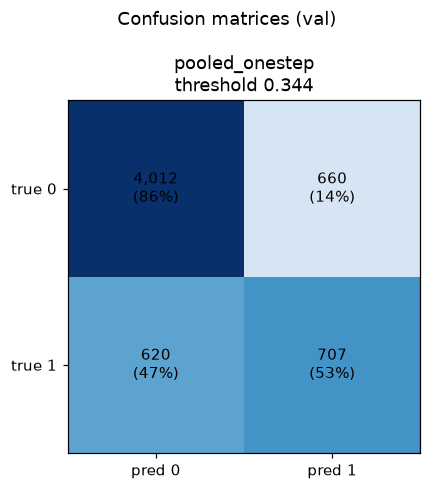
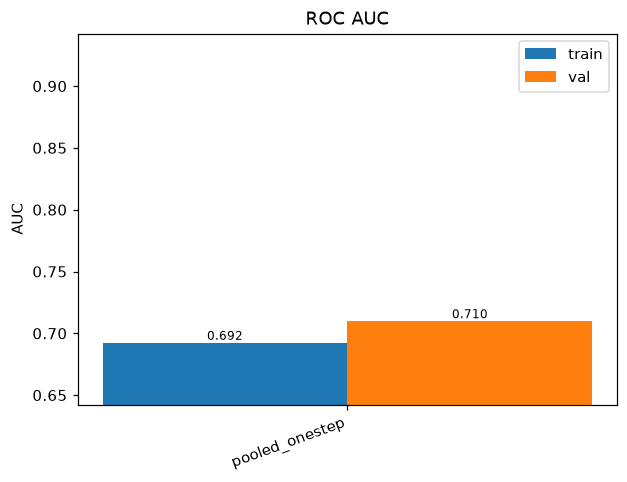
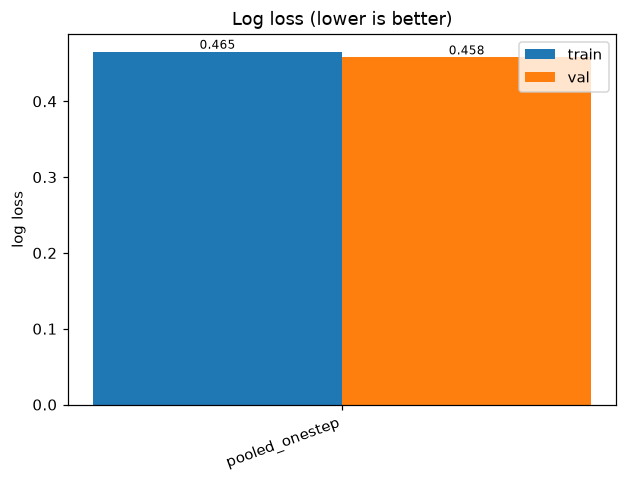
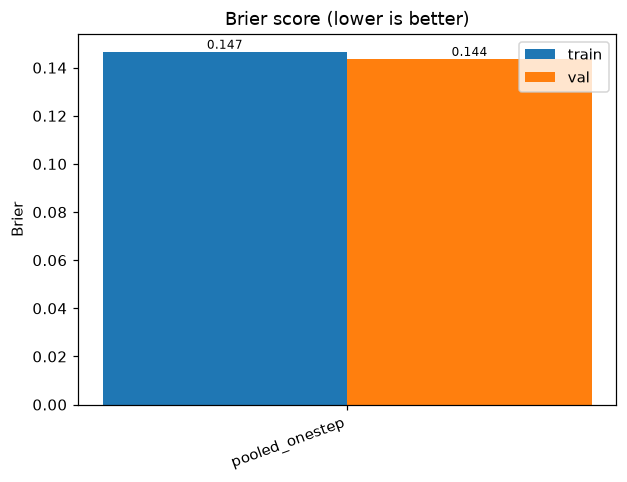
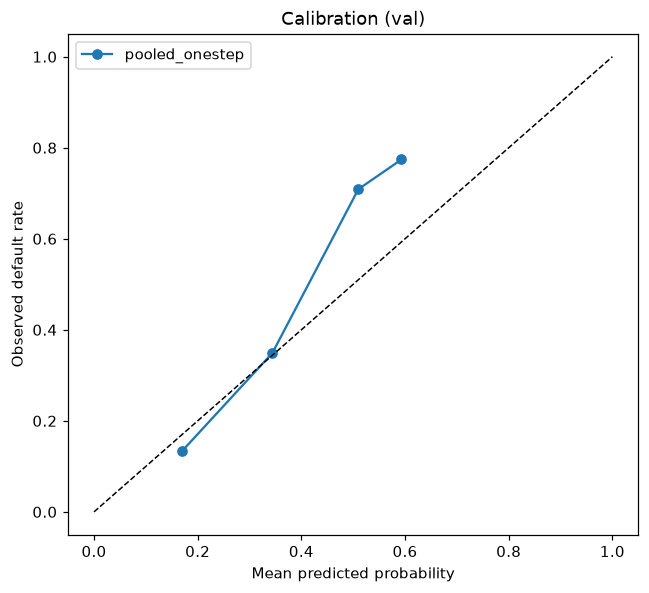

In [589]:
m = {"pooled_onestep": pooled}
show_row(
    lambda: plot_confusion(m, split="val"),
    lambda: plot_auc(m),
    lambda: plot_logloss(m),
    lambda: plot_brier(m),
    lambda: plot_calibration(m, split="val"),
)



## 2.6 Two Class Chain

For the next model, we will fit a separate chain for defaulters and non-defaulters and compare how the two classes behave.
For this model the training data is seperated into default and non-default classes and a markov chain is fit to each of them.

### 2.6.1 Constructing The Model

**1. Data and states**

For each customer (`PAY_6, ..., PAY_1`) denotes their payment status and $y \in \{0, 1\}$ denotes defaults: $1$ = default next month. The state mappings send each status into a bin

$$x_t = g(\text{PAY}_t) \in \{1, \dots, K\}, \qquad \mathbf{x} = (x_1, x_2, \dots, x_T).$$

For the new two class model, we will fit it with different bins which we can then compare and see how it affects the results. In 
These first will give a 5 state chain while the second will only give a 4 state chain by also splitting the final state into two.

In [590]:
# ---- state mappings ----
def make_to_state(mapping, top):
    # mapping: dict raw value -> state; any raw value >= top maps to the last state
    def f(p):
        p = np.asarray(p); s = np.empty(p.shape, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        s[p >= top] = max(mapping.values()) + 1 if top > max(mapping) else mapping[top]
        return s
    return f
# #function for each split of the Markov model
#original 5 states
def to_state_5full(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s

#merges -2, -1 and 0 into one state (not late)
def to_state_4nolate(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s


**2. Fit one chain per class**
Let $\mathcal{D}_c = \{ i : y_i = c \}$ for $c \in \{0, 1\}$ and let $\alpha = 1$ be the Laplace constant.

**Initial distribution** (state in the first month):

$$\pi_c(s) = \frac{\alpha + \sum_{i \in \mathcal{D}_c} \mathbf{1}[x_{i,1} = s]}{|\mathcal{D}_c| + K\alpha}.$$

**Transition matrix** from pooled consecutive pairs:

$$N_c(a,b) = \sum_{i \in \mathcal{D}_c} \sum_{t=1}^{T-1} \mathbf{1}[x_{i,t} = a,\; x_{i,t+1} = b],$$

$$P_c(a,b) = \frac{N_c(a,b) + \alpha}{\sum_{b'} N_c(a,b') + K\alpha}, \qquad \sum_{b} P_c(a,b) = 1.$$

In [591]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    #------2. Fit the Markov chain to the training data for each class (default and non-default)-------# 
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    
    #--------5. Fit a Platt scaling model to the validation set to calibrate the scores into probabilities.----------#
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m



**3. Sequence likelihood under each class**

Assuming a first-order, time-homogeneous Markov chain:

$$\Pr(\mathbf{x} \mid y = c) = \pi_c(x_1) \prod_{t=1}^{T-1} P_c(x_t, x_{t+1}).$$

**4. Posterior odds (Bayes' rule)**

With prior $\hat{p} = \Pr(y = 1)$ estimated on train:

$$\frac{\Pr(y=1 \mid \mathbf{x})}{\Pr(y=0 \mid \mathbf{x})}
= \frac{\Pr(\mathbf{x} \mid y=1)}{\Pr(\mathbf{x} \mid y=0)} \cdot \frac{\hat{p}}{1-\hat{p}}.$$

Taking logs gives the score used in the code (`llr`):

$$s(\mathbf{x}) = \underbrace{\log\frac{\pi_1(x_1)}{\pi_0(x_1)}}_{\text{start}}
+ \sum_{t=1}^{T-1} \underbrace{\log\frac{P_1(x_t, x_{t+1})}{P_0(x_t, x_{t+1})}}_{\text{transition } t}
+ \underbrace{\log\frac{\hat{p}}{1-\hat{p}}}_{\text{prior}}.$$

Each transition contributes its log-ratio $\lambda(a,b) = \log P_1(a,b) - \log P_0(a,b)$, the quantity shown in the log-ratio heatmap. $\lambda > 0$ pushes towards default; $\lambda < 0$ pushes away.

**5. Calibration (validation split)**

The chain's independence assumptions make $s$ overconfident, so $s$ is mapped to a probability by logistic (Platt) scaling fitted on the **validation** set:

$$\Pr(y = 1 \mid \mathbf{x}) = \sigma\big(a\, s(\mathbf{x}) + b\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

If $a = 1$ and $b = 0$, this reduces to the exact Bayes posterior.

**6. Assumptions and limitations**

- **First order:** $x_{t+1}$ depends only on $x_t$, not on earlier history.
- **Time-homogeneous:** the same $P_c$ applies at every step.
- **Sparse classes:** defaulters are about 22% of the data, so $P_1$ rests on fewer transitions. Rows with small $\sum_b N_c(a,b)$ are dominated by $\alpha$.
- **Leakage control:** $\pi_c, P_c, \hat{p}$ use train only; $(a, b)$ uses validation only; test is held out for evaluation.

### 2.6.2 Choosing States

Now that we have our model, we need to consider the different ways in which we can split up. We looked at 6 ways of grouping the `PAY` into markov states. This would be a lot to compare so only the three most intersting splits will be detailed more thoroughly in this chapter. The choices we made are as follows.

| Split | States | K | Val Brier | Decision |
|---|---|---|---|---|
| `mk5_full` | −2 · −1 · 0 · 1 · 2+ | 5 | 0.1391 | **Kept** |
| `mk4_nolate` | {−2, −1, 0} · 1 · 2 · 3+ | 4 | 0.1392 | **Kept** |
| `mk4_12` | {−2, −1} · 0 · {1, 2} · 3+ | 4 | 0.1405 | **Kept** |
| `mk4_01` | −2 · −1 · {0, 1} · 2+ | 4 | 0.1395 | Dropped |
| `mk5_12` | −2 · −1 · 0 · {1, 2} · 3+ | 5 | 0.1406 | Dropped |
| `mk4_late` | −2 · −1 · 0 · 1+ | 4 | 0.1407 | Dropped |


**Why the three were kept**

The kept splits give two intersting comparisons:

- **`mk5_full` vs `mk4_nolate`:** does separating the not-late statuses (no bill, paid, revolving) matter? Their scores are almost identical, so the finer split may add little information.
- **`mk4_nolate` vs `mk4_12`:** does merging the 1 and 2 months late states, which fixes the sparse "1 late" row, cost predictive accuracy? It costs about 0.0013 in validation Brier score.

**Why the other three were dropped**

- **`mk4_01`:** it merges revolving credit (0) with one month late (1), which puts an on-time status together with a late one. The result is also behind the two best splits on both validation and test.
- **`mk4_late`:** it merges every late status into one state, losing the difference between 1, 2 and 3+ months late. It has the worst validation score of the six.
- **`mk5_12`:** it performs essentially the same as `mk4_12` (0.1406 vs 0.1405) but has an extra state and therefore sparser rows, so the 4-state version replaces it.

**Selection rule and caveats**

Splits were removed using validation results and the reasoning above, so the test set stays unseen until the final comparison. The differences between splits are small (about 0.0003 to 0.0015 in Brier score) and we have not yet tested whether they are larger than sampling noise. The dropped splits are therefore a simplification, not a claim that they are proven worse. Where scores are indistinguishable, we prefer fewer states and better data support per transition.

In [592]:
# raw PAY value -> state; every value >= top goes to the final state
STATE_SPECS = {
    "mk5_full":   dict(map={-2:0,-1:1,0:2,1:3},     top=2, labels=["no bill","paid","revolving","1 late","2+ late"]),
    "mk4_nolate": dict(map={-2:0,-1:0,0:0,1:1,2:2}, top=3, labels=["on time","1 late","2 late","3+ late"]),
    "mk4_12":     dict(map={-2:0,-1:0,0:1,1:2,2:2}, top=3, labels=["no bill/paid","revolving","1-2 late","3+ late"]),
}

def _to_state_fn(mapping, top):
    last = max(mapping.values()) + 1
    raw_vals = list(mapping)
    def f(p):
        p = np.asarray(p)
        s = np.full(p.shape, last, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        bad = (p < top) & ~np.isin(p, raw_vals)
        if bad.any():
            raise ValueError(f"unmapped PAY values: {np.unique(p[bad])}")
        return s
    return f

def make_all_states(specs=STATE_SPECS):
    out = {}
    for name, sp in specs.items():
        K = max(sp["map"].values()) + 2          # mapped states + one final "top" state
        labels = sp.get("labels")
        if labels is not None and len(labels) != K:
            raise ValueError(f"{name}: {len(labels)} labels but K={K}")
        out[name] = dict(to_state=_to_state_fn(sp["map"], sp["top"]), K=K, labels=labels)
    return out

states = make_all_states()
markov_models = {n: build_markov(n, s["to_state"], s["K"]) for n, s in states.items()}
labels_all    = {n: s["labels"] for n, s in states.items()}

### 2.6.3 Matrix Heatmaps

The two-class chain is defined by two transition matrices, $P_0$ for non-defaulters and $P_1$ for defaulters. By plotting them we can check whether the model has learned behaviour that sounds reasonable, and where its estimates can be trusted. For each state split we show four panels:

- **$P_0$ and $P_1$:** the probability of moving from this month's state (rows) to next month's state (columns) for each class. Strong diagonals mean customers tend to stay in the same state.
- **$P_1 - P_0$:** the difference between the classes. Positive (red) cells are moves that defaulters make more often, while negative (blue) cells show moves more likely to be made by non-defaulters.
- **$\log(P_1/P_0)$:** the contribution of each transition to the model's score (the log-likelihood ratio). Positive values push a customer's score towards default, negative values away from it. Cells with fewer than 30 observed transitions in either class are greyed out as unreliable.

Because a probability estimated from few observations can be misleading, we follow each set of heatmaps with count heatmaps showing how many transitions each cell is based on, and how many customers leave each state. Rows with very few transitions are flagged, and these are the main reason for merging states in the next section.

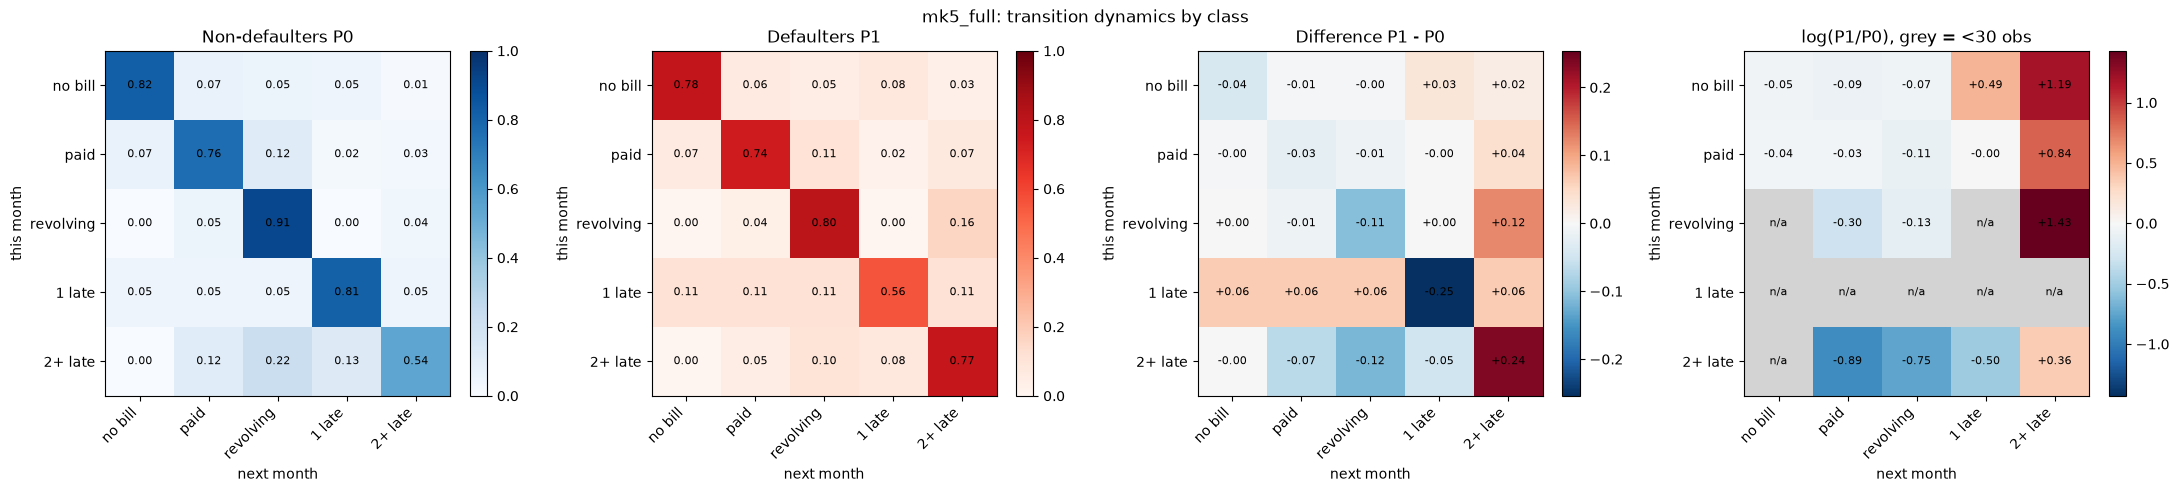

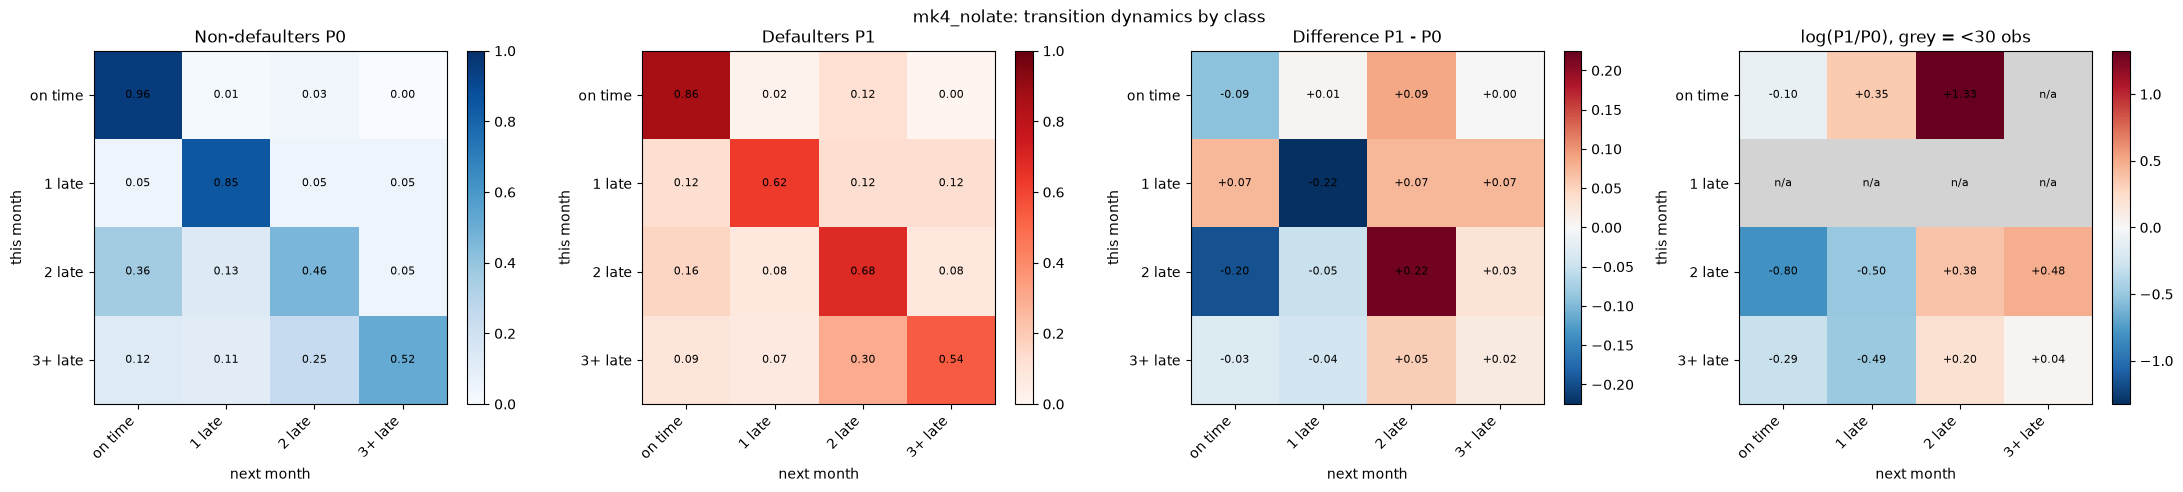

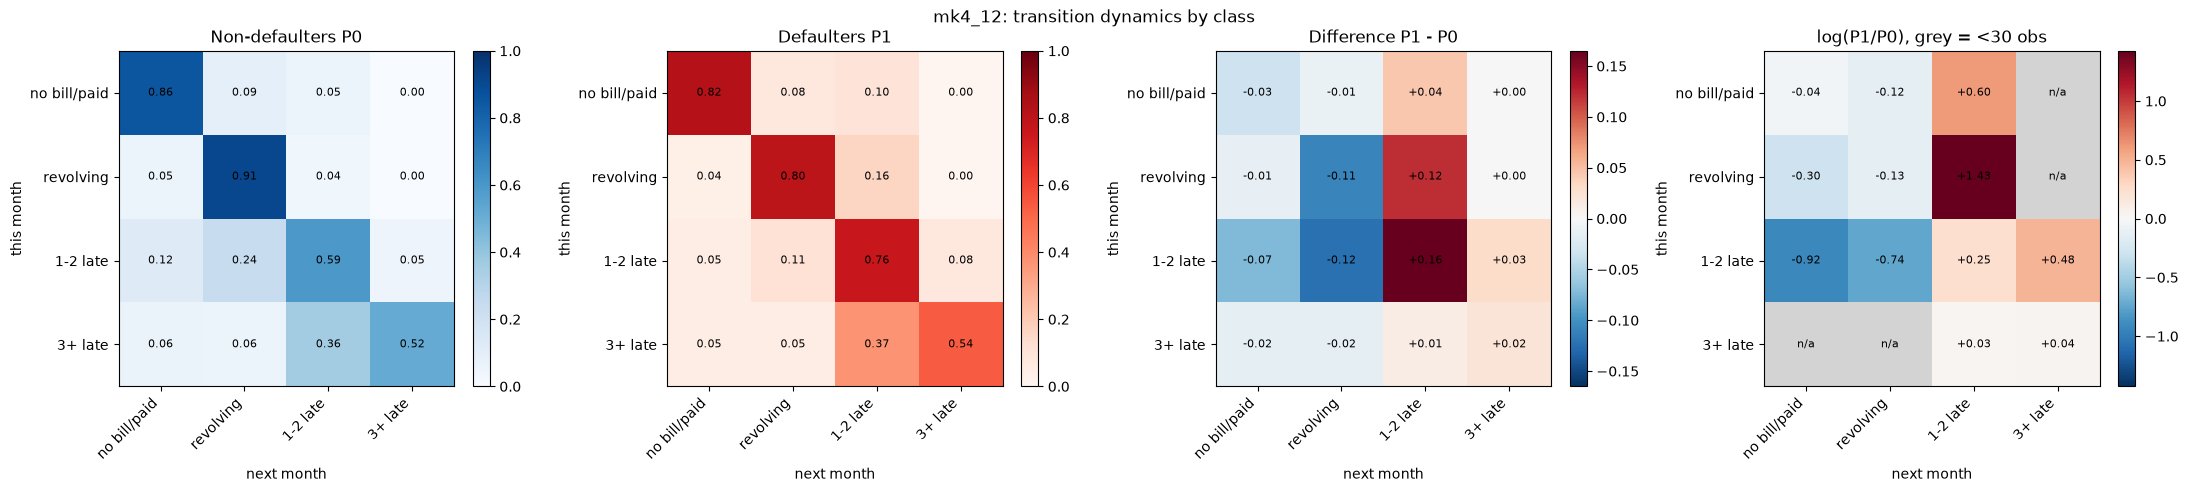

In [593]:
def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def _prep(key, models, labels, data, pay_cols, y):
    m = models[key]; K = m["K"]
    lab = labels[key] if isinstance(labels, dict) else list(labels)
    assert len(lab) == K, f"{key}: {len(lab)} labels but K={K}"
    y = np.asarray(y)
    S = m["to_state"](data[pay_cols].values)
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    return m, K, lab, C0, C1

def _tick_labels(ax, lab):
    K = len(lab)
    ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(lab)
    ax.set_xlabel("next month"); ax.set_ylabel("this month")


def plot_class_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(22, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < min_n
    diff, logr = P1 - P0, np.log(P1) - np.log(P0)
    logr_m = np.ma.array(logr, mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr_m).max()

    fig, axs = plt.subplots(1, 4, figsize=figsize)
    panels = [(P0, "Non-defaulters P0", "Blues", 0, 1, ".2f"),
              (P1, "Defaulters P1", "Reds", 0, 1, ".2f"),
              (diff, "Difference P1 - P0", cm, -dl, dl, "+.2f"),
              (logr_m, f"log(P1/P0), grey = <{min_n} obs", cm, -ll, ll, "+.2f")]
    for ax, (M, t, cmap, lo, hi, fmt) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                txt = "n/a" if (M is logr_m and low[i, j]) else format(M[i, j], fmt)
                ax.text(j, i, txt, ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
        _tick_labels(ax, lab)
    fig.suptitle(f"{key}: transition dynamics by class")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1, low=low)

for k in markov_models:
    plot_class_heatmaps(k, markov_models, labels_all, train, pay_cols, y_tr)




**Interpretation of Heatmaps**


*Persistence:* Regardless of split it is clear to see that the diagonals dominate. The non defaulters are more stable in the on-time states (e.g. 0.96 on time in `mk4_nolate`), while the defaulters are less stable in comparison (0.86 in `mk4_nolate`). They are also more persistent in late states (e.g. 0.68 vs 0.46 for "2 late" in `mk4_nolate`). A caveat of this is that non-defaulters seem to be more stable in 1 month late (0.81 vs 0.56 in `mk5_full`), however this is explained in the next section.

*What separates the classes:* The log-ratio panels show that the model's score is driven mainly by two kinds of transition. Moving from a not-late state into a late state is strong evidence of default (log ratios of +0.8 to +1.4 into "2+ late" in `mk5_full`), whereas leaving a late state for a non-late one is evidence against it (−0.5 to −0.9). Transitions out of the most delinquent state are close to zero, so being in "3+ late" is only weakly informative about the class by itself.

*Reliability:* The "1 late" row in `mk5_full` and `mk4_nolate` is greyed out: it is based on fewer than 30 transitions. Its off-diagonal entries are all identical (0.05 for non-defaulters, 0.11 for defaulters), which is what Laplace smoothing produces when counts are near zero. The apparent result that non-defaulters stay "1 late" more often than defaulters (0.85 vs 0.62) is therefore a smoothing artefact, not real behaviour. In `mk4_12`, merging "1 late" and "2 late" removes this problem: the merged row is well supported and gives the expected pattern, with defaulters staying late (0.76 vs 0.59) and non-defaulters recovering more often.

*Implication:* The chains pick up plausible class-specific behaviour, and the main signal comes from entering and leaving delinquency. The sparse "1 late" state is the main weakness of the finer splits, which is why we compare it with merged versions in the next section.
The P0 and P1 matrices both have strong diagonal enteries. Defaulters are less stable in the not late states which matches general intuition which is a good sign. The weakest P0 diagonal being the 2+ late with a value of only 0.54 Here there is a 34% chance of returning to an on time payment. This behavour is not seen in P1 which has a much stronger 0.77 diagonal entry and only a 15% chance of returning to a non late status. What is less expected is the non defaulters are more likely to remain 1 month over than defaulters. This result is likely an artifact of smoothing due to the limited data size of the 1 late row.


### 2.6.4 Count Heatmaps

The probabilities in the heatmaps are estimated from counts of month-to-month transitions, so each estimate is only as reliable as the number of observations behind it.The figure below shows these counts for the 5-state split `mk5_full`: the raw transition counts for non-defaulters and defaulters (log colour scale, with cells below 30 observations in bold), and the total number of transitions out of each state for each class. The training set has 17,997 customers, giving 89,985 transitions.

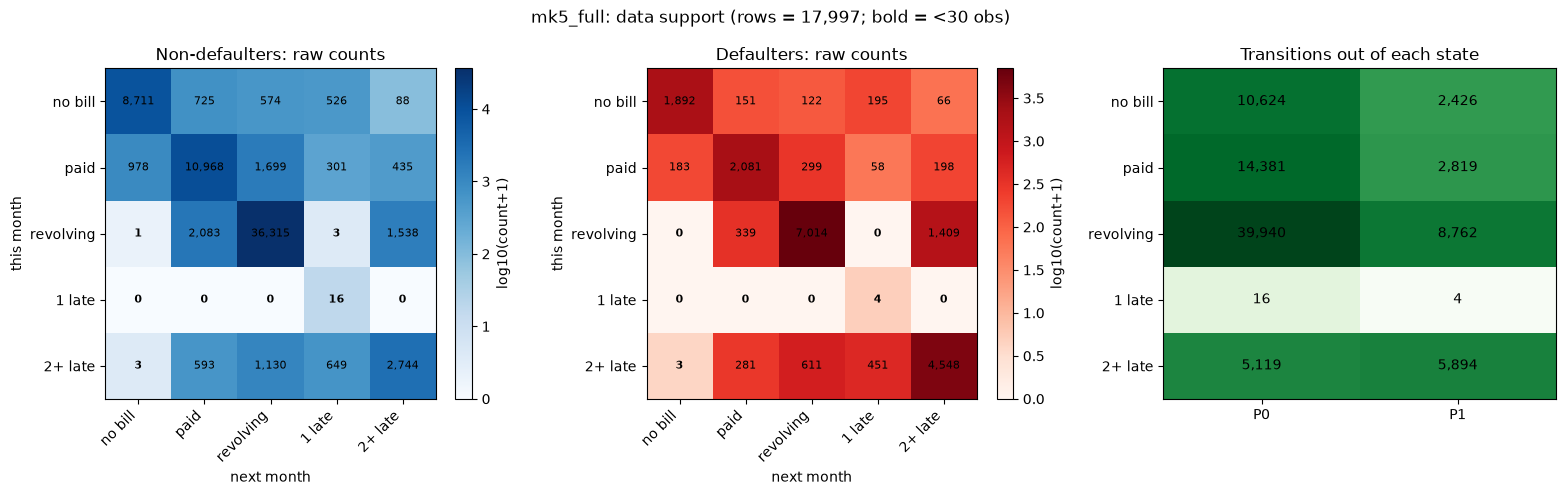

In [594]:
MIN_N = 30  # cells with fewer raw transitions than this are flagged as unreliable

def plot_count_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(16, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)

    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for ax, C, t, cmap in [(axs[0], C0, "Non-defaulters: raw counts", "Blues"),
                           (axs[1], C1, "Defaulters: raw counts", "Reds")]:
        im = ax.imshow(np.log10(C + 1), cmap=cmap); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{C[i, j]:,}", ha="center", va="center", fontsize=8,
                        fontweight="bold" if C[i, j] < min_n else "normal")
        plt.colorbar(im, ax=ax, fraction=0.046).set_label("log10(count+1)")
        _tick_labels(ax, lab)

    row_n = np.vstack([C0.sum(1), C1.sum(1)]).T
    axs[2].imshow(np.log10(row_n + 1), cmap="Greens", aspect="auto")
    for i in range(K):
        for c in range(2):
            axs[2].text(c, i, f"{row_n[i, c]:,}", ha="center", va="center")
    axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(["P0", "P1"])
    axs[2].set_yticks(range(K)); axs[2].set_yticklabels(lab)
    axs[2].set_title("Transitions out of each state")

    fig.suptitle(f"{key}: data support (rows = {len(data):,}; bold = <{min_n} obs)")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1)


plot_count_heatmaps("mk5_full", markov_models, labels_all, train, pay_cols, y_tr);

**Findings.**
- Most states are well supported. Every state other than "1 late" has at least 2,400 transitions out of it for each class.
- As defaulters have fewer observations overall (19,905 transitions against 70,080), their estimates are less precise than the non-defaulters', although still adequate enough to use.
- The "1 late" state is the exception: only 16 transitions for non-defaulters and 4 for defaulters. Every transition out of it is therefore dominated by the Laplace smoothing, this explains the non-defaulters stability in 1 month late. It is just an artifact of the lack of data in those rows being dominated by the laplace smoothing rather than a meaningful behavoural difference.
- A few other cells are very sparse (below 30), for example revolving to "1 late" (3 and 0) and "2+ late" to "no bill" (3 and 3). These are transitions that rarely or never happen, rather than a lack of data.
- "1 late" is entered far more often than it is left (about 2,200 transitions into it, against 20 out of it), so it behaves mostly as a one-off state at the end of a customer's sequence.

We will keep `mk5_full` in the comparison as the finest split, but interpret its "1 late" row with caution, because it reflects the smoothing prior rather than observed behaviour. Because so few transitions involve this state, its effect on predictions is small, but the sparse row is the main weakness of the finer splits. This motivates comparing merged splits in the next section.

### 2.6.5 Comparison

In this section we compare the baseline pooled chain with the three two-class splits we kept (`mk5_full`, `mk4_nolate`, `mk4_12`). We want to answer two questions: 
- Is the two-class chain a clear improvement over the baseline?  
- Which state split should be carried forward?

State splits were screened on the validation set

We use several metrics because each measures something different:
- **AUC** measures how well a model ranks defaulters above non-defaulters. It is unaffected by how well the probabilities are calibrated.
- **Log loss and Brier score** measure the quality of the predicted probabilities, so they penalise a model whose probabilities are wrong even if its ranking is good.
- **Calibration and cumulative-gains curves** show where probabilities are too high or too low, and how many defaulters are captured by targeting the highest-risk customers.
- **Confusion matrices** show errors at a fixed threshold. Each threshold was chosen on the validation set by maximising TPR − FPR, so the thresholds differ between models and the matrices are not directly comparable. We therefore use them to illustrate behaviour and not to rank models.

Two points affect how fair the comparison is. The two-class models are Platt-scaled on the validation set while the baseline is not, so some of their advantage in log loss, Brier score and calibration may come from calibration alone; AUC is not affected by this. Differences between splits are also small, so we judge them using their sampling variability (bootstrap intervals) and not point estimates alone.

We call an improvement clear if it holds across the metrics and exceeds this variability. If the splits are indistinguishable, we choose the one with the fewest states and the best data support per transition.


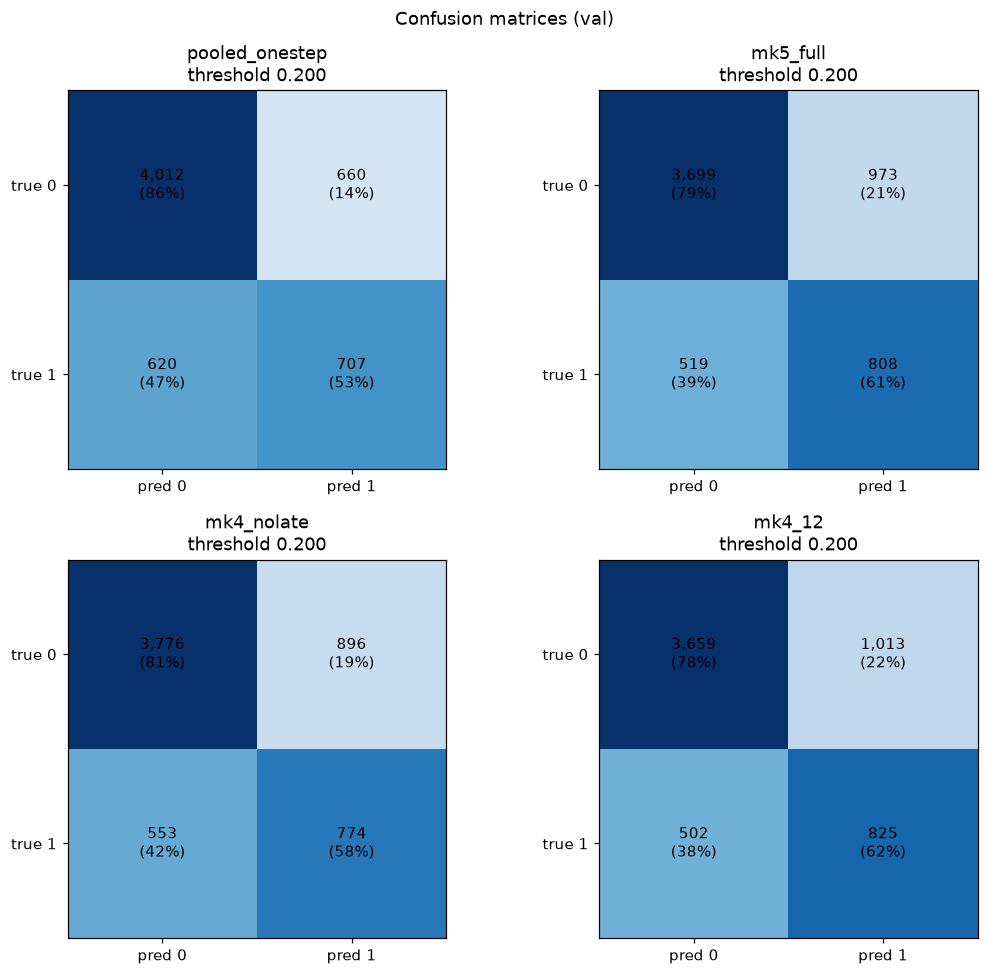
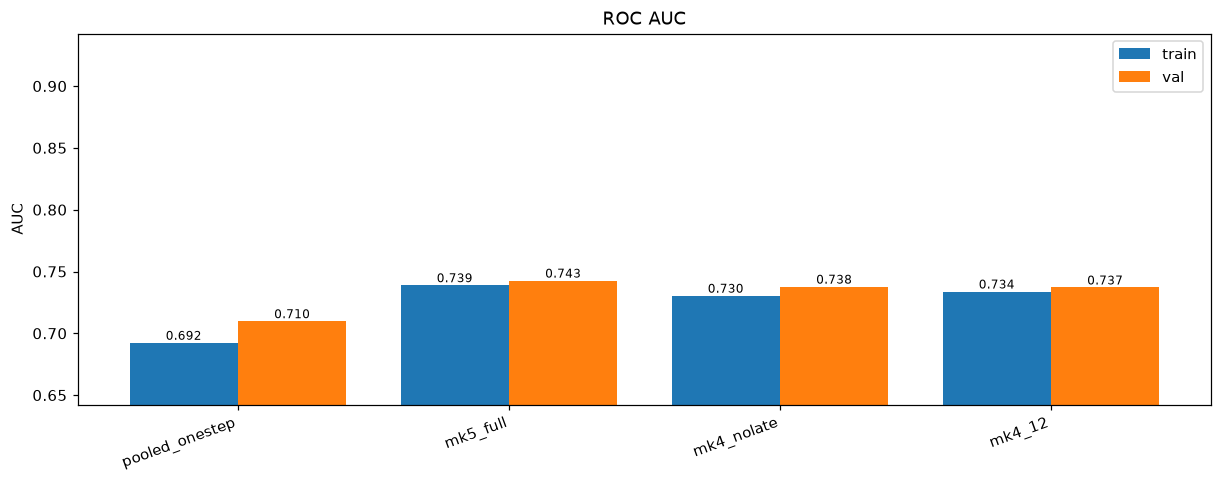
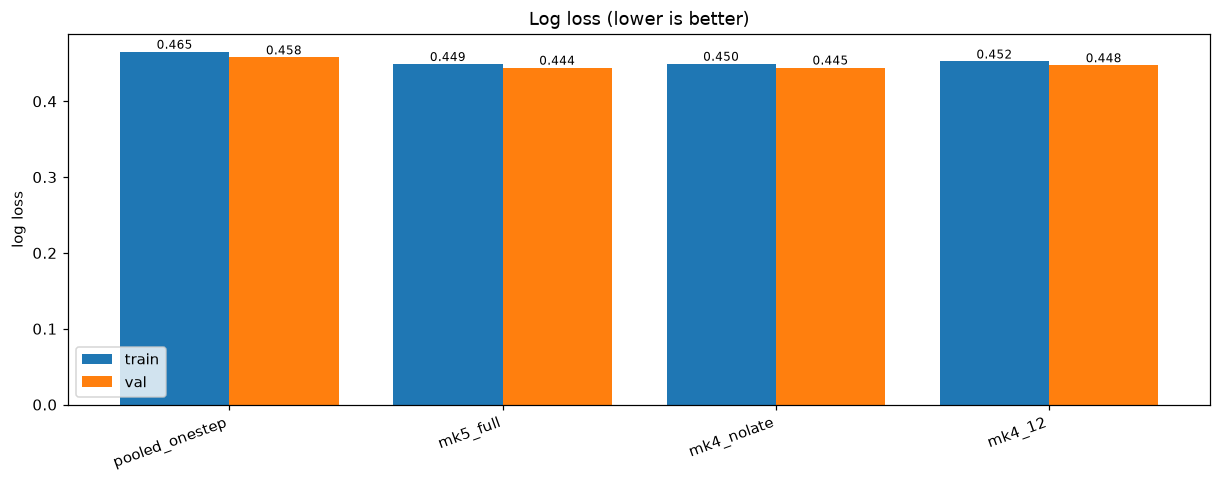
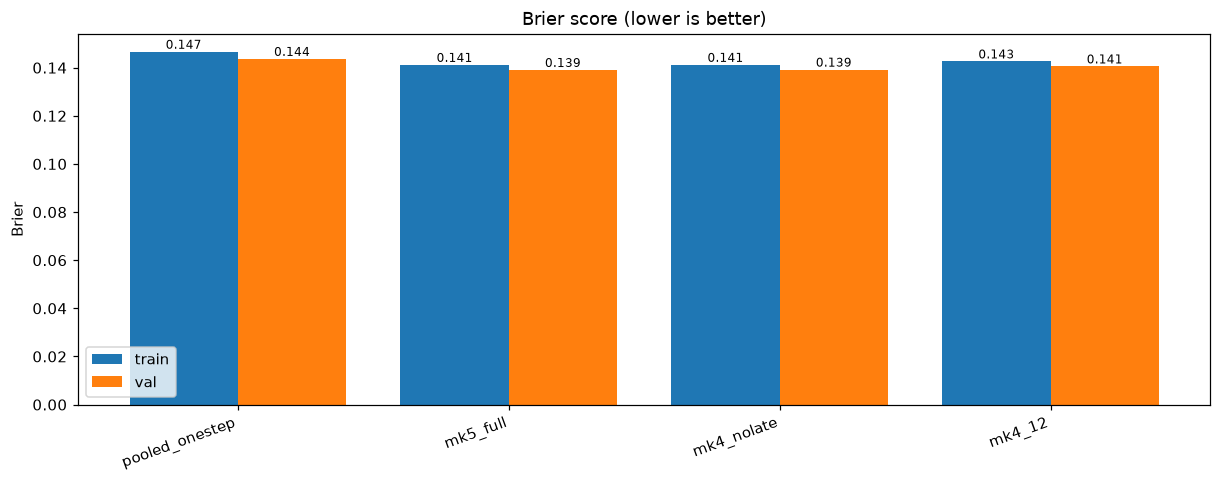


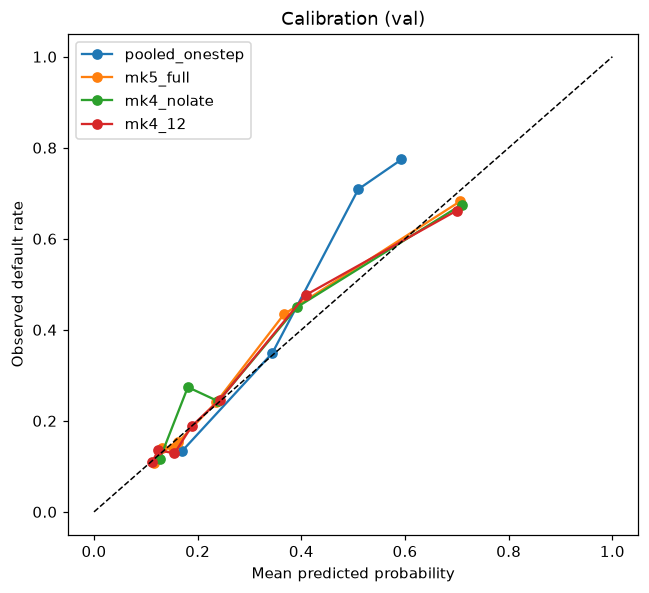
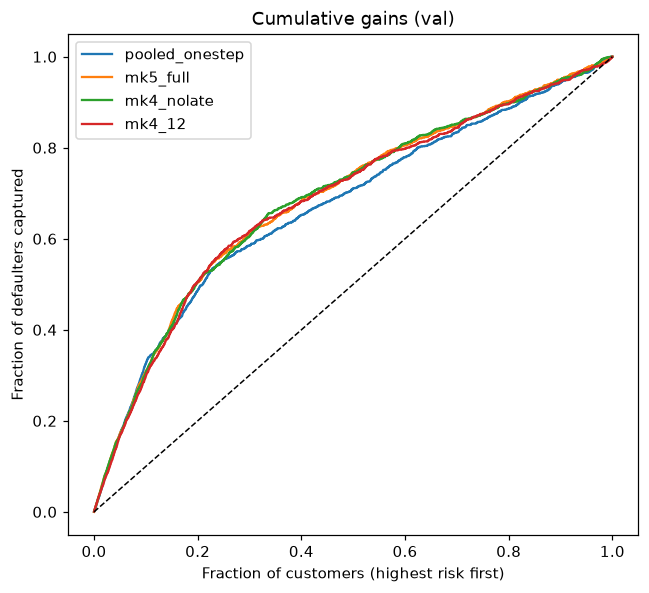
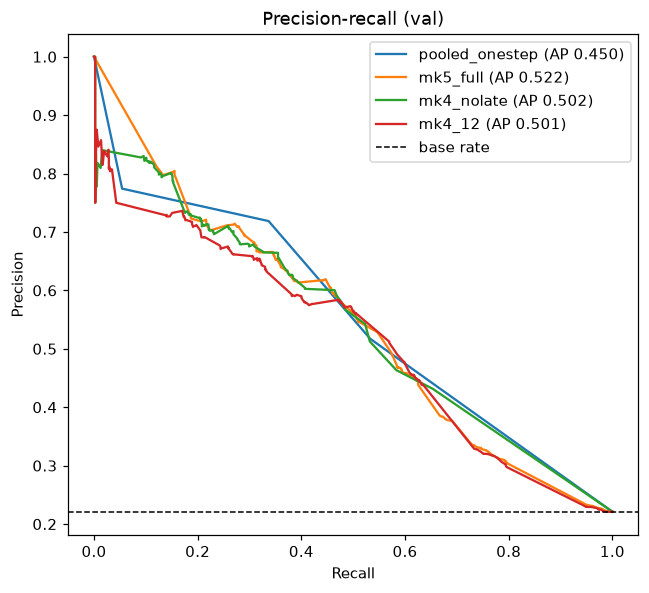
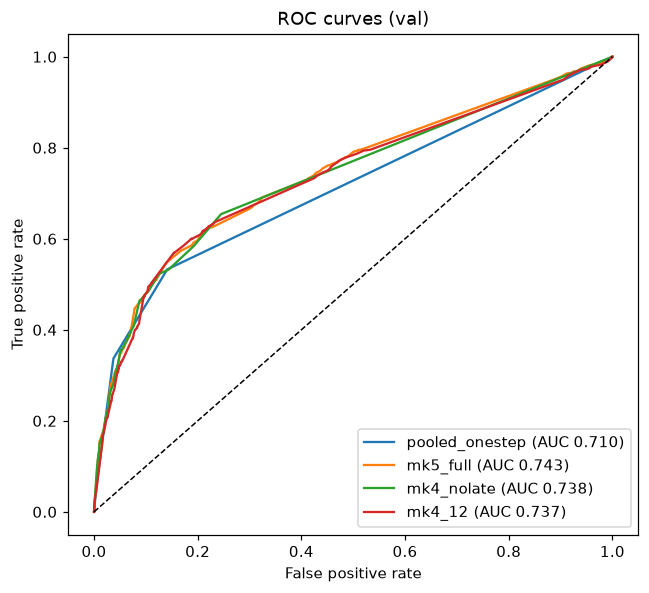

In [595]:
compare = {"pooled_onestep": pooled, "mk5_full": markov_models["mk5_full"], "mk4_nolate": markov_models["mk4_nolate"], "mk4_12": markov_models["mk4_12"]}
show_row(
    lambda: plot_confusion(compare, split="val",thresholds={"pooled_onestep": 0.2, "mk5_full": 0.2, "mk4_nolate": 0.2, "mk4_12": 0.2}),
    lambda: plot_auc(compare),
    lambda: plot_logloss(compare),
    lambda: plot_brier(compare),

    width=1000
)

show_row(
    lambda: plot_calibration(compare, split="val"),
    lambda: plot_gains(compare),
    lambda: plot_pr(compare),
    lambda: plot_roc(compare),
    width=500
)

**Interpretation**

mk4_12

## 2.7 Supplementary Data

### 2.7.1 Method

The goal of this next section is to investigate if the two class chain can be further improved upon by utilising supplimentary data to distinguish new chain states. We will use how much they owe along with payment status in order to be able to better distinguish the exact patterns of defaulters compared to non-defaulters. 

Each month's state combines the payment state $s_{i,t}$ and the debt bin $b_{i,t}$:

$$
x_{i,t} = (s_{i,t},\, b_{i,t}), \qquad K = K_{\text{pay}} \times B
$$

For an initial test of this model we will use a smaller `mk_3` model (to limit size) and compare possible choices we can make abouth this model. For the 3-state payment split (current/paid, revolving, late) with 3 debt bins this gives $K = 9$ states and 81 transition cells per class. The model is otherwise unchanged: one chain is fitted per class with Laplace smoothing, customers are scored by the log-likelihood ratio of their sequence plus the class prior, and the score is calibrated with Platt scaling on the validation set.

The chain can now learn two new things that payment status alone cannot show:

- whether the same payment state means different risk at different debt levels (for example, a late customer with a large balance versus a small one), and
- whether the way debt moves from month to month differs between defaulters and non-defaulters (for example, debt growing while the customer stays revolving).



In [596]:

def debt_matrix(d, measure="util"):
    bill = np.clip(d[bill_cols].values.astype(float), 0, None)       # chronological Apr..Sep
    return bill / d["LIMIT_BAL"].values[:, None] if measure == "util" else bill

def fit_chain_aug(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha
    C = np.full((K, K), alpha)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return init / init.sum(), C / C.sum(1, keepdims=True)

def llr_aug(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov_debt(name, base_to_state, K_base, base_labels=None, n_bins=3,
                      measure="util", split=None, alpha=1.0):
    # debt-bin edges from TRAIN only
    D_tr = debt_matrix(train, measure)
    edges = np.unique(np.quantile(D_tr.ravel(), np.linspace(0, 1, n_bins + 1)[1:-1]))
    nb = len(edges) + 1
    split = set(range(K_base) if split is None else split)   # base states to subdivide by debt

    lookup, labels, k = np.zeros((K_base, nb), dtype=int), [], 0
    for s in range(K_base):
        base = base_labels[s] if base_labels else str(s)
        if s in split:
            for b in range(nb):
                lookup[s, b] = k; k += 1; labels.append(f"{base} | debt {b+1}/{nb}")
        else:
            lookup[s, :] = k; k += 1; labels.append(base)
    K = k

    def encode(d):
        s = base_to_state(d[pay_cols].values)
        return lookup[s, np.digitize(debt_matrix(d, measure), edges)]

    S_tr, S_va, S_te = encode(train), encode(validation), encode(test)
    ytr = np.asarray(y_tr).astype(int)
    init0, P0 = fit_chain_aug(S_tr[ytr == 0], K, alpha)       # TRAIN only
    init1, P1 = fit_chain_aug(S_tr[ytr == 1], K, alpha)
    m = dict(name=name, K=K, labels=labels, edges=edges, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(ytr.mean() / (1 - ytr.mean())))
    m["S_tr"], m["y_tr"] = S_tr, y_tr
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr_aug(S_tr, m), llr_aug(S_va, m), llr_aug(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION only
    return m



### 2.7.2 Data Selection

Debt could be measured by using credit utilisation instead of raw bill, where negaive bills are clipped to zero. This allows customers with different credit limits to be compared with one another instead of just using the raw bill value. Then statuses are seperated by percentage of credit limit accessed. For three the limit is split into thirds.
$$
u_{i,t} = \frac{\max(\text{BILL\_AMT}_{i,t},\, 0)}{\text{LIMIT\_BAL}_i}
$$

**Correlation**

Before we decide on this as our metric we want to check it is the better option as we dont want to risk losing performance. We will first test how differently the two options segment the training data by calculating the Spearman correlation. We use Spearman's rank correlation, because the bins are defined by quantiles and so only the ordering of values matters, and a cross-tabulation of the three-bin splits the model would actually use.




In [597]:
b_tr = debt_matrix(train, "bill").ravel()
u_tr = debt_matrix(train, "util").ravel()
print("Spearman correlation:", spearmanr(b_tr, u_tr)[0])

def terciles(x): return np.digitize(x, np.quantile(x, [1/3, 2/3]))
print(pd.crosstab(terciles(b_tr), terciles(u_tr), normalize="index").round(2))

Spearman correlation: 0.8379257483447687
col_0     0     1     2
row_0                  
0      0.91  0.09  0.00
1      0.09  0.58  0.32
2      0.00  0.33  0.67


The spearman correlation of 0.838 is reasonably high which, so they carry largely the same information and there is little reason to expect a gain from including both. The table shows where the mismatches are occuring: about 72% of observations fall in the same bin, and no observation moves by more than one bin (both corner cells are 0.00). Agreement is highest in the lowest bin (91%) and lowest in the middle bin (58%), where a medium bill can become a high or low utilisation depending on the credit limit. We therefore expect the two choices to perform similarly. In that case utility will still be justified as it is more interpretable for clients with varying credit limits.



**Paired Bootstrap**

Similar bins do not guarantee similar performance, so we test it directly. We use a debt-free `mk3` two-class chain as the control and build debt models for each measure (raw bill and utilisation) with 2, 3 and 4 bins. For each pair of models we resample the validation customers with replacement 1,000 times and compute the difference in AUC on each resample. Using the same resampled customers for both models makes the comparison paired, which gives a tighter interval than comparing the two models separately. We report the 95% interval of the difference. AUC is computed on the raw scores, so the comparison does not depend on calibration. 


In [598]:
import numpy as np, pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

# --- 1. add mk3 and rebuild the state dictionary ---
STATE_SPECS["mk3"] = dict(
    map={-2: 0, -1: 0, 0: 1},                        # current/paid, revolving
    top=1,                                            # every status >= 1 month late -> one state
    labels=["current/paid", "revolving", "late (1+)"],
)
states = make_all_states(STATE_SPECS)
base = states["mk3"]
assert base["K"] == 3, base["labels"]
print(base["K"], base["labels"], np.bincount(base["to_state"](train[pay_cols].values).ravel()))

# --- 2. fast bootstrap helpers ---
def make_boot_idx(n, B=1000, seed=0):
    return np.random.default_rng(seed).integers(0, n, (B, n))        # same resamples for every model

def boot_auc(y, s, idx):
    yb, r = y[idx], rankdata(np.asarray(s)[idx], axis=1)             # ranks handle ties correctly
    npos = yb.sum(1); nneg = idx.shape[1] - npos
    return ((r * yb).sum(1) - npos * (npos + 1) / 2) / (npos * nneg)  # Mann-Whitney AUC per resample

def diff_ci(a, b):
    d = a - b
    return d.mean(), tuple(np.percentile(d, [2.5, 97.5]))

# --- 3. build models once, bootstrap each once ---
y_va_a = np.asarray(y_va)
idx = make_boot_idx(len(y_va_a))
control = build_markov("mk3", base["to_state"], base["K"])           # no debt
boot = {"mk3": boot_auc(y_va_a, control["sc_va"], idx)}               # control computed once

models, rows = {}, []
for measure in ("util", "bill"):
    for nb in (2, 3, 4):
        name = f"mk3_{measure}{nb}"
        m = models[name] = build_markov_debt(name, base["to_state"], base["K"],
                                             base_labels=base["labels"], n_bins=nb, measure=measure)
        boot[name] = boot_auc(y_va_a, m["sc_va"], idx)
        diff, (lo, hi) = diff_ci(boot[name], boot["mk3"])
        rows.append(dict(measure=measure, bins=nb, K=m["K"], val_AUC=roc_auc_score(y_va_a, m["sc_va"]),
                         AUC_gain_vs_nodebt=diff, CI_low=lo, CI_high=hi))
results = pd.DataFrame(rows).round(4)
results

3 ['current/paid', 'revolving', 'late (1+)'] [35357 57536 15089]


,measure,bins,K,val_AUC,AUC_gain_vs_nodebt,CI_low,CI_high
0,util,2,6,0.7479,0.0108,0.0047,0.0171
1,util,3,9,0.7619,0.0247,0.0159,0.0342
2,util,4,12,0.7628,0.0256,0.0146,0.0366
3,bill,2,6,0.7512,0.0140,0.0060,0.0220
4,bill,3,9,0.7590,0.0220,0.0122,0.0317
5,bill,4,12,0.7549,0.0178,0.0068,0.0279


**Comparison**

What is instantly good to see is that the debt data improves all models as the low intervals are all positive. For the difference between util and bill however there is no clear leader from this data. This does at least mean that it is unlikley that using utlitly is significantly limiting the model so we will go forward with it on the grounds of interpretability. Now looking at the bins 3 bins has a significant AUC gain over using only two bins but is barely improved by a 4th bin so to balance sparcity and size of the model we will select three bins as standard.


### 2.7.3 Model Creation

To follow directly from the previous development, along with our `mk3_debt` model we will develop two versions of the `mk4_12` model. One using two bins the other using three to compare gains across different sized transition matrices.


In [599]:
# blank model: the same 3 payment states, no debt
mk3 = build_markov("mk3", base["to_state"], base["K"])

# debt model: 3 payment states x 3 debt bins = 9 states
mk3_debt = build_markov_debt("mk3_debt", base["to_state"], base["K"],
                             base_labels=base["labels"], n_bins=3, measure="util")

# 4 payment states x 3 debt bins = 12 states
mk4_12_debt = build_markov_debt("mk4_12_debt", states["mk4_12"]["to_state"], states["mk4_12"]["K"],
                                base_labels=states["mk4_12"]["labels"], n_bins=3)

# 4 payment states x 2 debt bins = 8 states
mk4_12_debt_2 = build_markov_debt("mk4_12_debt_2", states["mk4_12"]["to_state"], states["mk4_12"]["K"],
                                  base_labels=states["mk4_12"]["labels"], n_bins=2, measure="util")

debt_models = {"mk3_debt": mk3_debt, "mk4_12_debt": mk4_12_debt, "mk4_12_debt_2": mk4_12_debt_2}

### 2.7.4 Heatmaps

**Cost.** Multiplying the number of states by $B$ multiplies the number of transition cells by $B^2$, so each cell is estimated from fewer transitions. Because of the larger number of cells it is morel likely there will be low count cells. Cells with fewer than 30 observations in either class are greyed out in the heatmaps, and their probabilities are dominated by smoothing.
 
We will limit the number of bins, by looking at which splits look most valuable on the heatmap. 
Then compare against the same payment split without debt and full debt to check that the added information outweighs the added sparsity.

**Sensitivity.** We test the choice of debt measure (utilisation or raw bill), the number of bins ($B=2,3,4$), and whether to subdivide all payment states or only the revolving and late ones. The results are compared on validation AUC.



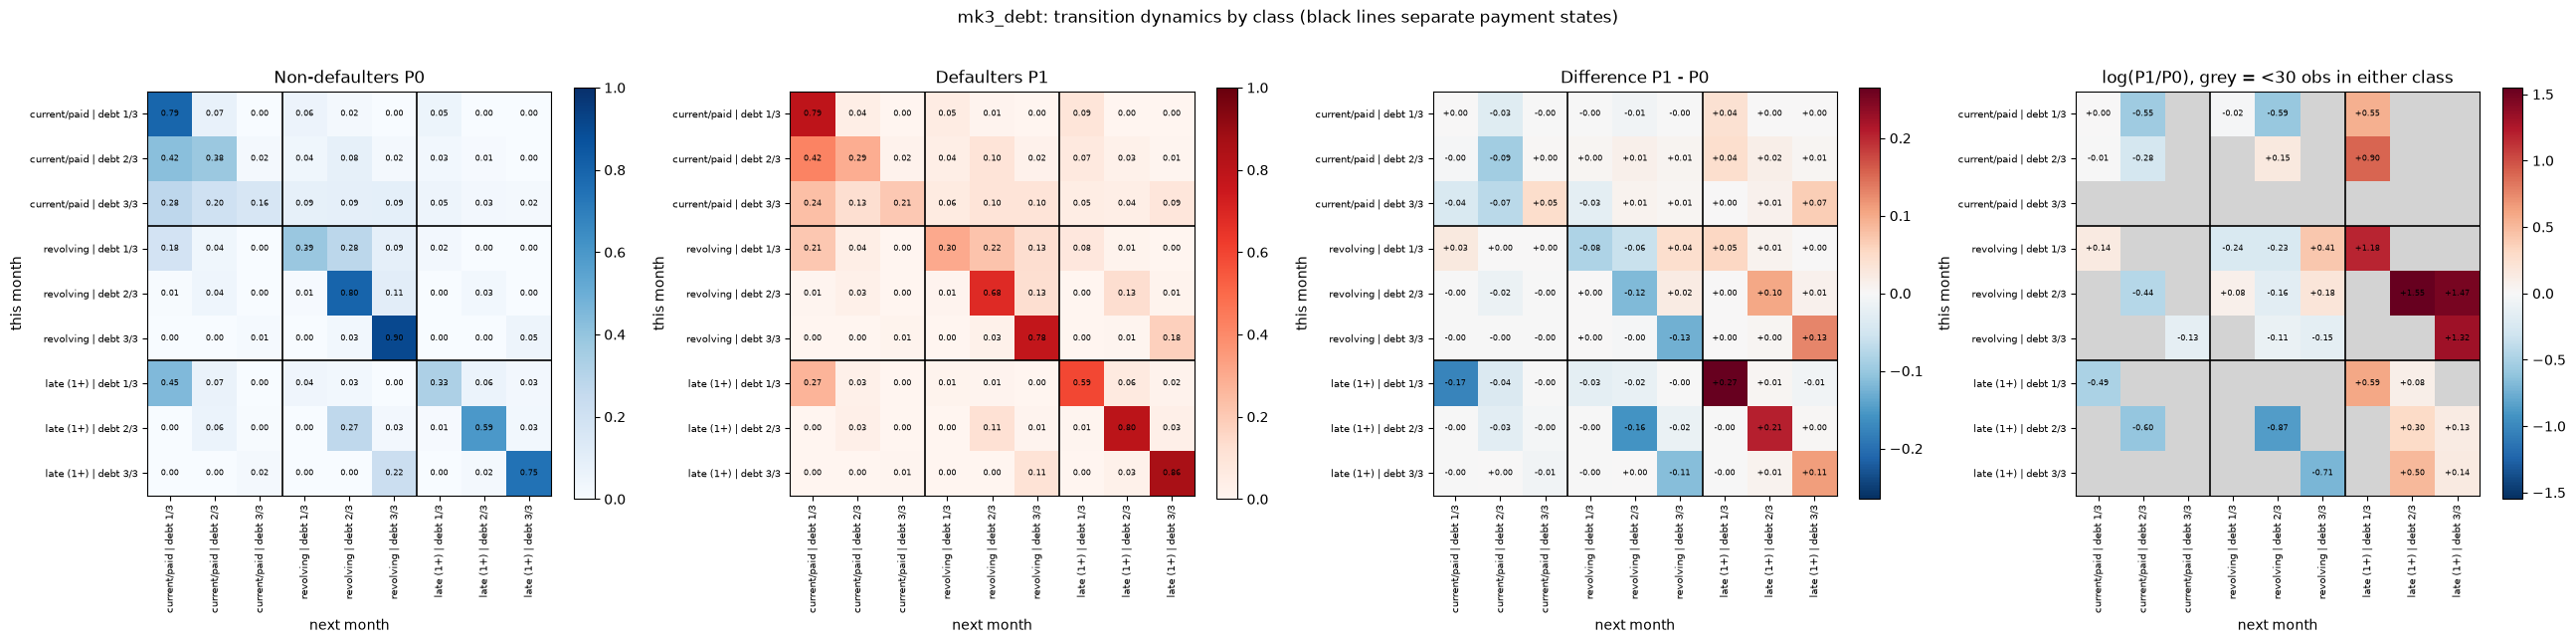

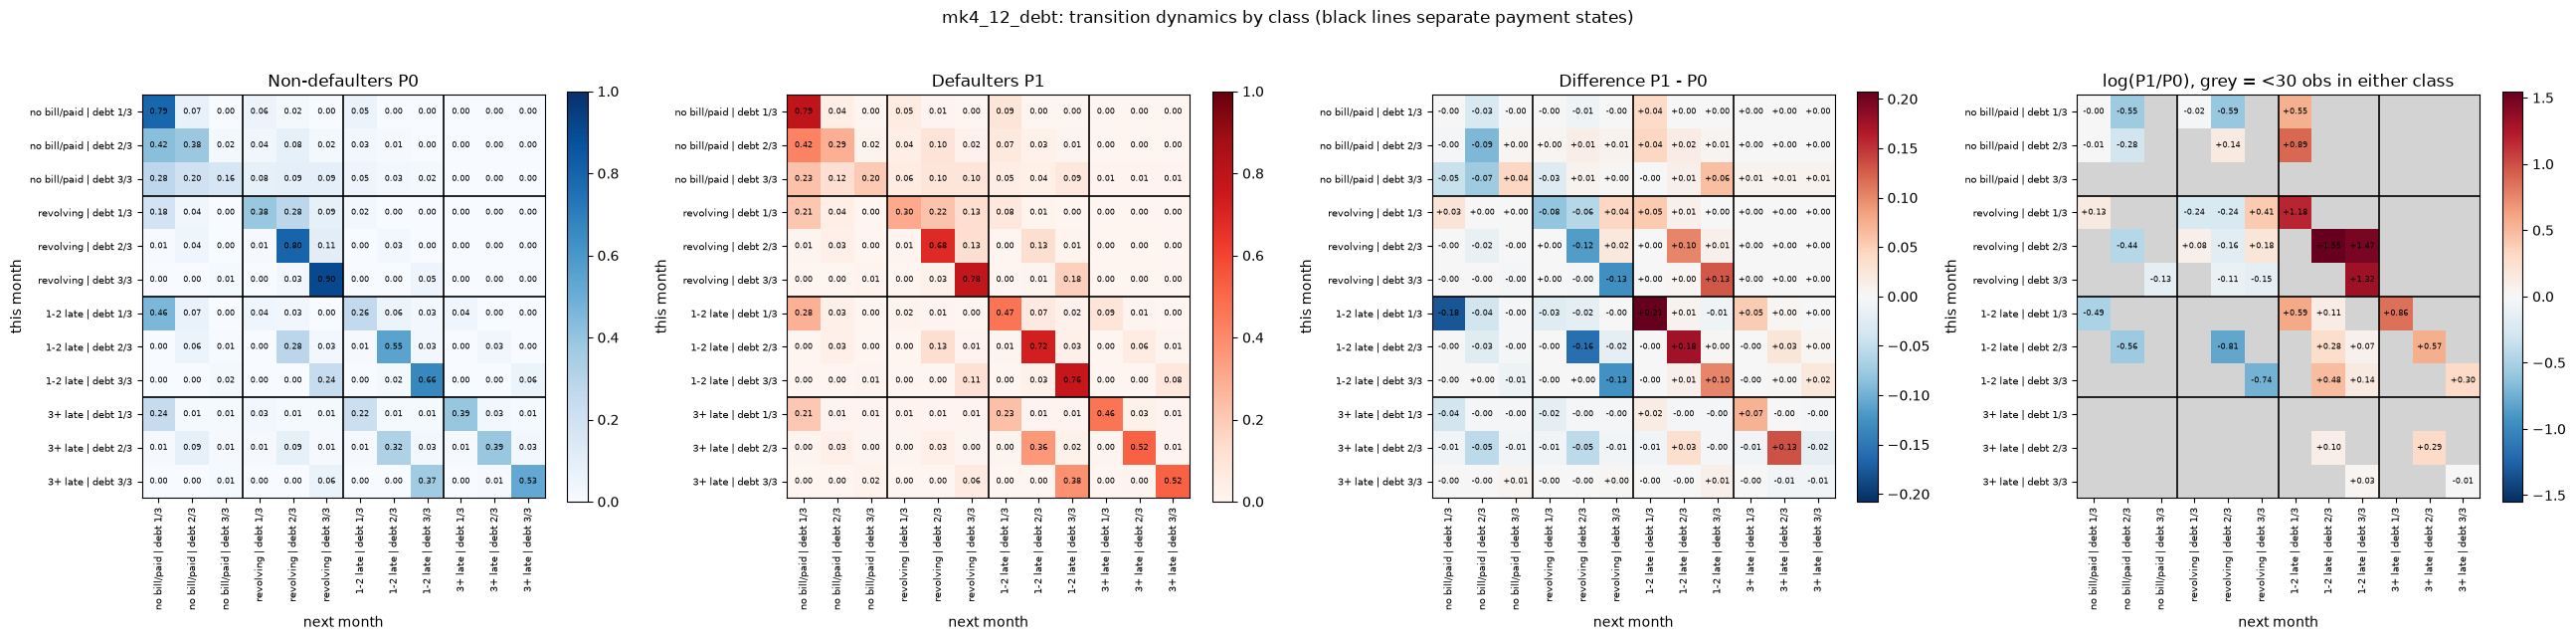

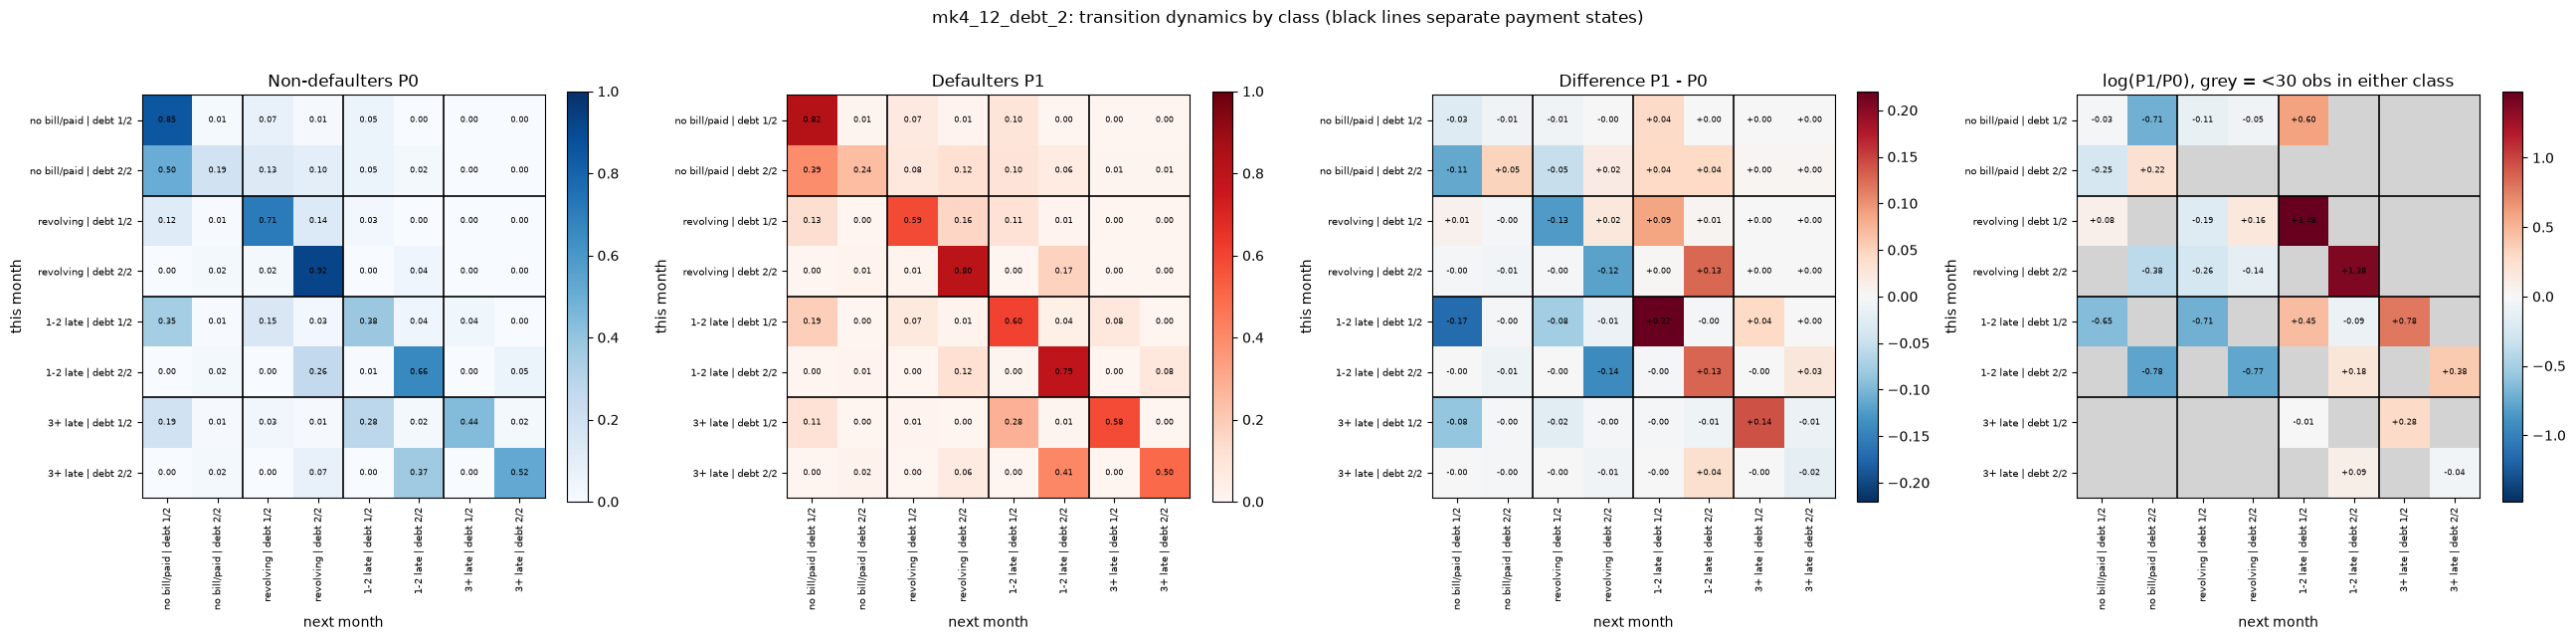

In [600]:
m["S_tr"], m["y_tr"] = S_tr, y_tr

import numpy as np, matplotlib.pyplot as plt

def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def plot_debt_heatmaps(m, minn=30, figsize=(26, 6.5), fs=6):
    K, lab = m["K"], list(m["labels"])
    S, y = m["S_tr"], np.asarray(m["y_tr"])
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < minn                         # unreliable cells
    diff = P1 - P0
    logr = np.ma.array(np.log(P1) - np.log(P0), mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr).max()

    base = [l.split(" | ")[0] for l in lab]                 # group by payment state
    cuts = [i - 0.5 for i in range(1, K) if base[i] != base[i - 1]]

    panels = [("Non-defaulters P0", P0, "Blues", 0, 1),
              ("Defaulters P1", P1, "Reds", 0, 1),
              ("Difference P1 - P0", diff, cm, -dl, dl),
              (f"log(P1/P0), grey = <{minn} obs in either class", logr, cm, -ll, ll)]
    fig, axs = plt.subplots(1, 4, figsize=figsize)
    for ax, (t, M, cmap, lo, hi) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi)
        ax.set_title(t)
        for i in range(K):
            for j in range(K):
                masked = M is logr and low[i, j]
                txt = "" if masked else (f"{M[i, j]:.2f}" if t.startswith(("Non", "Def")) else f"{M[i, j]:+.2f}")
                ax.text(j, i, txt, ha="center", va="center", fontsize=fs)
        for c in cuts:                                       # black lines between payment states
            ax.axhline(c, color="k", lw=1.2); ax.axvline(c, color="k", lw=1.2)
        ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=90, fontsize=7)
        ax.set_yticks(range(K)); ax.set_yticklabels(lab, fontsize=7)
        ax.set_xlabel("next month"); ax.set_ylabel("this month")
        plt.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{m['name']}: transition dynamics by class (black lines separate payment states)")
    plt.tight_layout(); plt.show()

for k in debt_models:
    plot_debt_heatmaps(debt_models[k])


### 2.7.5 Performance Testing


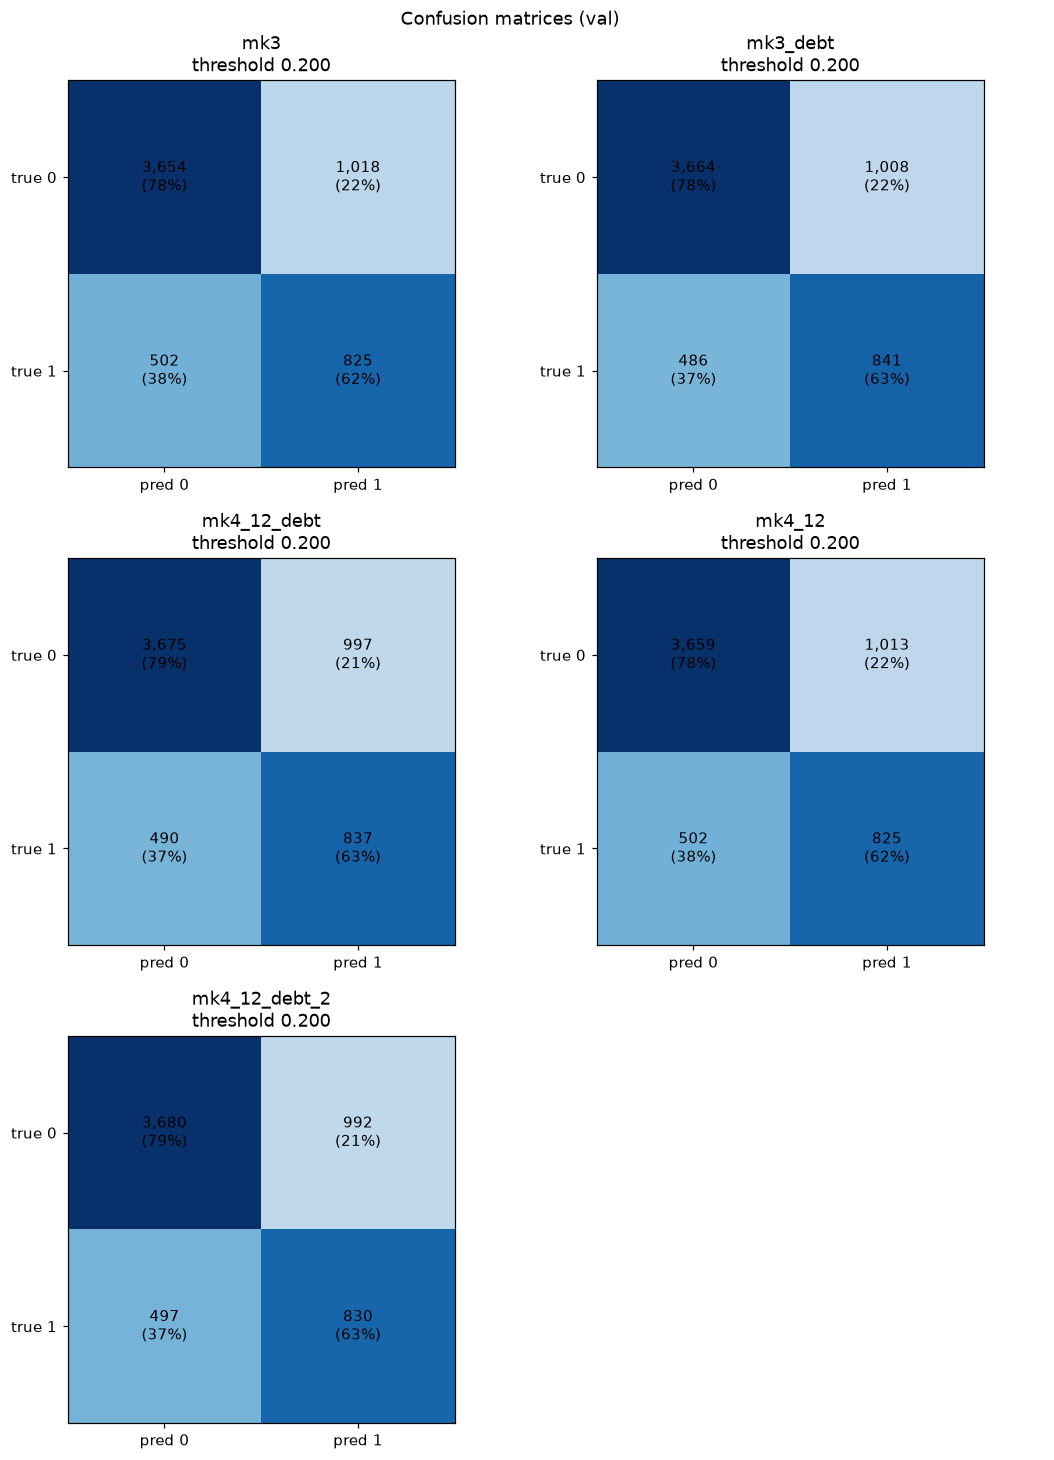
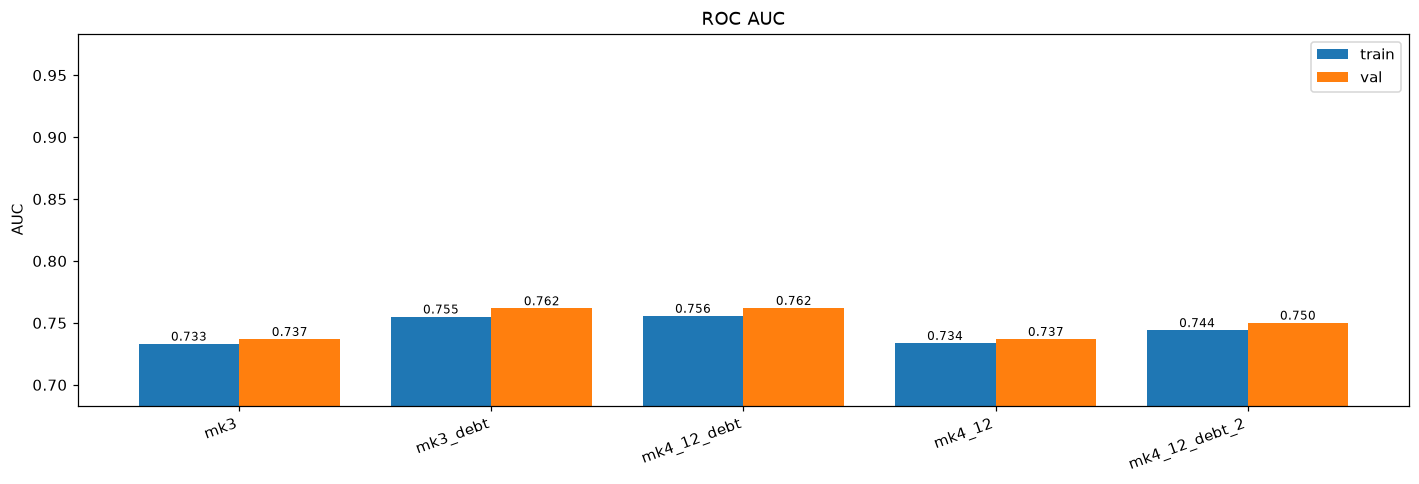
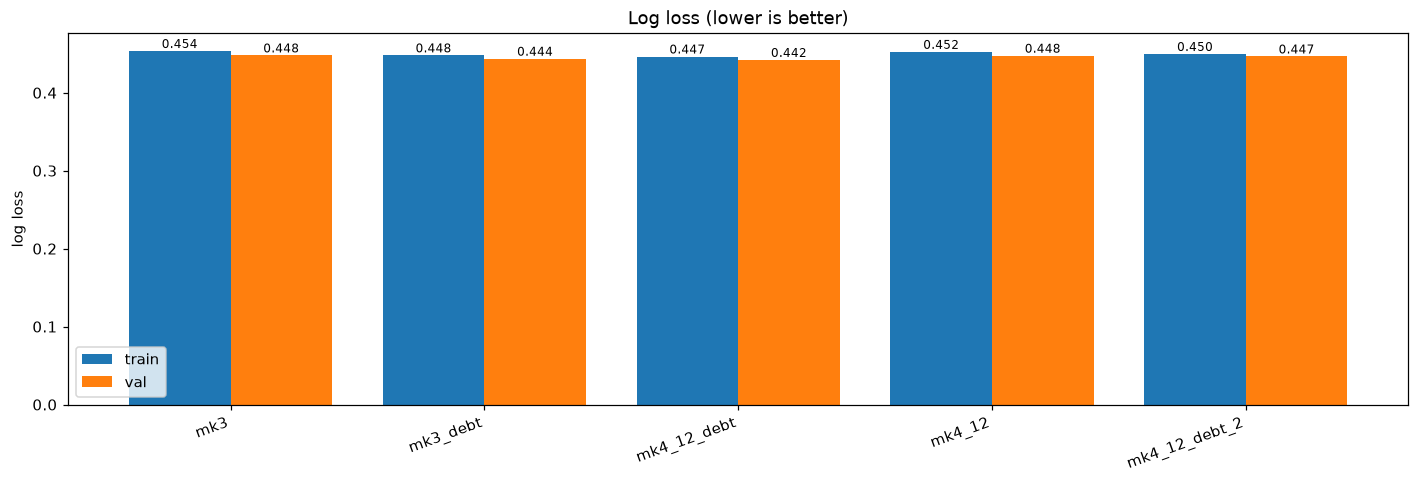
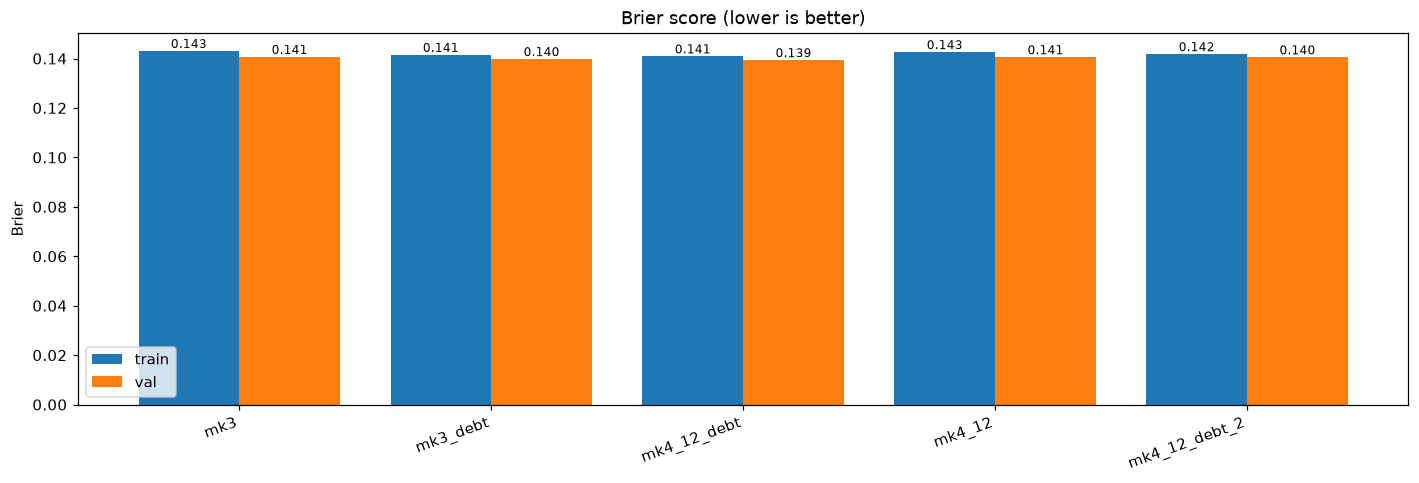

In [601]:

compare = {"mk3": mk3, "mk3_debt": mk3_debt, "mk4_12_debt": mk4_12_debt, "mk4_12": markov_models["mk4_12"], "mk4_12_debt_2": mk4_12_debt_2}
thresholds = {n: 0.2 for n in compare}
show_row(
    lambda: plot_confusion(compare, split="val", thresholds=thresholds),
    lambda: plot_auc(compare),
    lambda: plot_logloss(compare),
    lambda: plot_brier(compare),
    width=1000
)

## 2.8 Second Order Chain

In [602]:
import numpy as np
from sklearn.linear_model import LogisticRegression

def fit_chain2(S, K, alpha=1.0, lam=10.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha
    init = init / init.sum()
    C1 = np.full((K, K), alpha)                                     # first-order, Laplace smoothed
    np.add.at(C1, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    P_first = C1 / C1.sum(1, keepdims=True)
    N = np.zeros((K, K, K))                                         # counts N[a, b, c]
    np.add.at(N, (S[:, :-2].ravel(), S[:, 1:-1].ravel(), S[:, 2:].ravel()), 1)
    P2 = (N + lam * P_first[None, :, :]) / (N.sum(2, keepdims=True) + lam)
    return init, P_first, P2, N

def llr2(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    sc = sc + np.log(m["P_first1"][S[:, 0], S[:, 1]]) - np.log(m["P_first0"][S[:, 0], S[:, 1]])
    for t in range(1, S.shape[1] - 1):
        sc = sc + (np.log(m["P2_1"][S[:, t-1], S[:, t], S[:, t+1]])
                   - np.log(m["P2_0"][S[:, t-1], S[:, t], S[:, t+1]]))
    return sc + m["log_prior"]

def build_markov_order2(name, encode, K, labels=None, lam=10.0, alpha=1.0):
    """encode(df) -> integer state array of shape (n_customers, 6)."""
    S_tr, S_va, S_te = encode(train), encode(validation), encode(test)
    ytr = np.asarray(y_tr).astype(int)
    i0, F0, P0, N0 = fit_chain2(S_tr[ytr == 0], K, alpha, lam)      # TRAIN only
    i1, F1, P1, N1 = fit_chain2(S_tr[ytr == 1], K, alpha, lam)
    m = dict(name=name, K=K, labels=labels, lam=lam,
             init0=i0, init1=i1, P_first0=F0, P_first1=F1, P2_0=P0, P2_1=P1, N0=N0, N1=N1,
             log_prior=np.log(ytr.mean() / (1 - ytr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr2(S_tr, m), llr2(S_va, m), llr2(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION only
    return m

In [603]:
base = states["mk4_12"]
enc = lambda d: base["to_state"](d[pay_cols].values)
mk4_12_o2 = build_markov_order2("mk4_12_order2", enc, base["K"], labels=base["labels"], lam=10)

0.1 0.7438
1 0.7438
10 0.7439
100 0.7429
10000.0 0.7376
100000000.0 0.7371
non-defaulters rows with <30 obs: 4 of 16
defaulters rows with <30 obs: 3 of 16



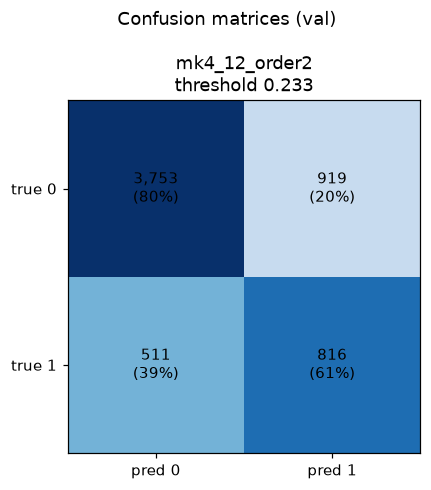
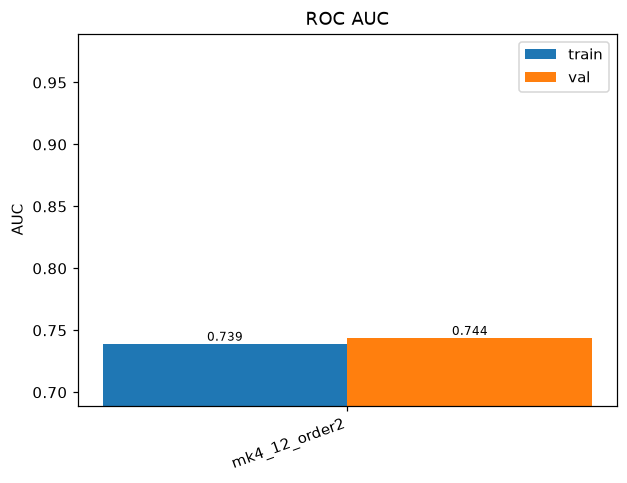
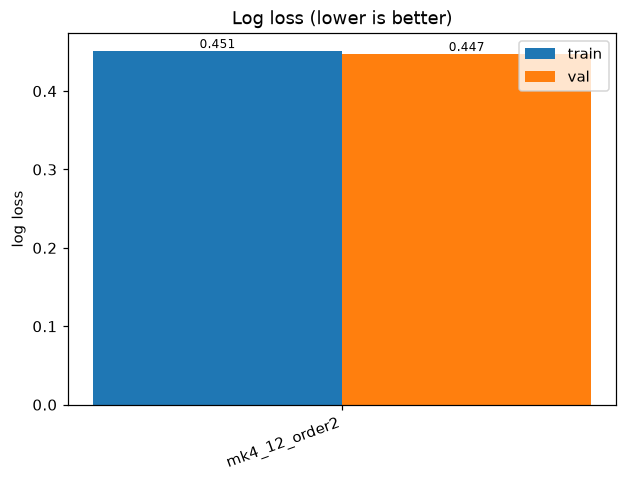
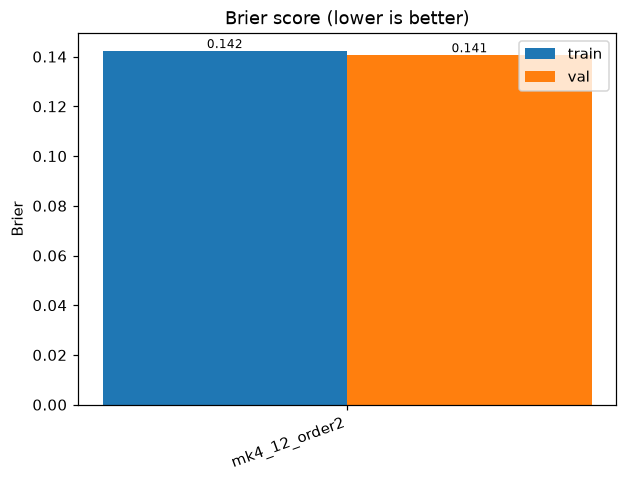

In [604]:
from sklearn.metrics import roc_auc_score
for lam in [0.1, 1, 10, 100, 1e4, 1e8]:
    m = build_markov_order2("o2", enc, base["K"], lam=lam)
    print(lam, round(roc_auc_score(y_va, m["sc_va"]), 4))

for c, N in [("non-defaulters", mk4_12_o2["N0"]), ("defaulters", mk4_12_o2["N1"])]:
    rows = N.sum(2)
    print(c, "rows with <30 obs:", int((rows < 30).sum()), "of", rows.size)

show_row(
    lambda: plot_confusion({"mk4_12_order2": mk4_12_o2}, split="val"),
    lambda: plot_auc({"mk4_12_order2": mk4_12_o2}),
    lambda: plot_logloss({"mk4_12_order2": mk4_12_o2}),
    lambda: plot_brier({"mk4_12_order2": mk4_12_o2}),
    width=500
)

**interpretation**

## 2.9 Conclusion